# Validação completa — classificação de tumor cerebral em RM
### Glioma · Meningioma · Notumor · Pituitary — YOLO11s-cls × EfficientNet-B0 (CNN)

Este notebook **valida** dois modelos já treinados (não treina nada) e está organizado em **3 etapas**:

| Etapa | Conteúdo |
|---|---|
| **Preparação** | Configuração, integridade dos dados (vazamento), carga dos modelos e das probabilidades, funções auxiliares |
| **ETAPA 1 — Avaliação do YOLO11s-cls** | Todas as análises feitas **só com o YOLO** |
| **ETAPA 2 — Avaliação da CNN (EfficientNet-B0)** | As **mesmas** análises, agora só com a CNN |
| **ETAPA 3 — Comparação entre os 2 modelos** | Lado a lado: métricas, ROC, log-loss, variância, treino, estatística, robustez, eficiência, checklist e conclusão |

**Análises de cada modelo (Etapas 1 e 2):** métricas por conjunto · **curvas ROC/PR** · **log-loss** · **acurácia treino × valid × teste (variância)** · **loss de treino e taxa de aprendizado** · matrizes de confusão · calibração e predição seletiva · visão clínica (tumor × sem tumor) · intervalos de confiança · teste limpo (sem vazamento) · robustez a perturbações · Grad-CAM · análise de erros · eficiência/determinismo · checklist de aprovação.

> **Como usar:** deixe este arquivo na pasta `Trabalho Faculdade` (a que contém `Treinamento_CNN` e `Treinamento_YOLO`) e **execute as células em ordem** (a Etapa 2 reutiliza as funções definidas na Etapa 1). Saídas em `resultados/` (nesta pasta), com prefixo `1_yolo_`, `2_cnn_` e `3_comp_`. Primeira execução ≈ 20–30 min em CPU; as probabilidades ficam em cache. Para uma versão rápida use `AVALIAR_TREINO = False`.

In [1]:
!pip install -q torch torchvision ultralytics scikit-learn scipy matplotlib pandas seaborn pyyaml

# PREPARAÇÃO
## P.1 Configuração

In [2]:
import os, io, time, json, glob, math, hashlib, warnings, random
from pathlib import Path
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from PIL import Image, ImageFilter, ImageEnhance
from scipy.stats import binomtest, norm
from scipy.spatial.distance import cdist
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
                             matthews_corrcoef, cohen_kappa_score, log_loss, roc_auc_score, roc_curve, auc,
                             precision_recall_curve, average_precision_score, classification_report, confusion_matrix)
from ultralytics import YOLO
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight"})

# ===================== CONFIGURAÇÕES — AJUSTE AQUI SE PRECISAR =====================
MODELO         = "efficientnet_b0"  # mesmo valor usado no treino da CNN
BATCH          = 32
NUM_WORKERS    = 0                  # 0 é o mais seguro no Windows
SEED           = 42
AVALIAR_TREINO = True               # avalia também o conjunto de treino (necessário p/ medir variância; ~10 min em CPU)
USAR_CACHE     = True               # guarda probabilidades em disco (apague a pasta cache/ se trocar os pesos)
N_BOOT         = 1000               # reamostragens do bootstrap
N_ROBUSTEZ     = 120                # nº de imagens de teste usadas nos testes de robustez
N_GRADCAM      = 6                  # nº de imagens com erro mostradas no Grad-CAM
DUP_LIM        = 2.0                # quase-duplicata = diferença média de pixel <= 2 (de 255) na miniatura 32x32

# Critérios de aprovação (checklist). São metas DEFINIDAS PELO GRUPO para este trabalho — não são padrões clínicos/regulatórios.
CRIT = dict(acc_teste_min=0.97, recall_classe_min=0.95, sens_tumor_min=0.99, gap_treino_val_max=0.03,
            gap_val_teste_max=0.02, auc_min=0.99, logloss_max=0.15, ece_max=0.03, queda_robustez_max=0.10)
# ====================================================================================

def achar_base():
    p = Path.cwd().resolve()
    for cand in [p, *p.parents]:
        if (cand / "Treinamento_CNN").exists() and (cand / "Treinamento_YOLO").exists(): return cand
    return p
BASE = achar_base()
PASTA_DADOS    = BASE / "Treinamento_CNN" / "Tumor-Cerebral-1"
PASTA_DADOS_Y  = BASE / "Treinamento_YOLO" / "Tumor-Cerebral-1"
PASTA_CNN      = BASE / "Treinamento_CNN" / "runs"
PASTA_YOLO_RUN = BASE / "Treinamento_YOLO" / "runs" / "classify" / "runs" / "yolo11s_lung_v2"
PESO_YOLO, PESO_CNN = PASTA_YOLO_RUN / "weights" / "best.pt", PASTA_CNN / f"{MODELO}_best.pt"
PASTA_SAIDA = BASE / "Validacoes" / "_anteriores" / "Validacao_Completa_3_etapas" / "resultados"; PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

NOME_Y, NOME_C = "YOLO11s-cls", "EfficientNet-B0"
MODELOS = [NOME_Y, NOME_C]
COR = {NOME_Y: "#d95f02", NOME_C: "#1b9e77"}
PRE = {NOME_Y: "1_yolo", NOME_C: "2_cnn"}            # prefixo dos arquivos salvos
SPLITS = ["train", "val", "test"] if AVALIAR_TREINO else ["val", "test"]
NOME_S = {"train": "treino", "val": "validação", "test": "teste"}
PASTA_S = {"train": "train", "val": "valid", "test": "test"}

def selecionar_device():
    if torch.backends.mps.is_available(): return torch.device("mps")
    if torch.cuda.is_available(): return torch.device("cuda")
    return torch.device("cpu")
device = selecionar_device()
def sincronizar():
    if device.type == "cuda": torch.cuda.synchronize()
    elif device.type == "mps": torch.mps.synchronize()
def salvar_fig(nome): plt.savefig(PASTA_SAIDA / nome, dpi=150); plt.show()
def salvar_tab(df, nome, index=True): df.to_csv(PASTA_SAIDA / nome, index=index)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

obrig = {"dados": PASTA_DADOS, "peso YOLO": PESO_YOLO, "peso CNN": PESO_CNN, "meta CNN": PASTA_CNN / f"{MODELO}_meta.json",
         "histórico CNN": PASTA_CNN / f"{MODELO}_historico.csv", "results.csv YOLO": PASTA_YOLO_RUN / "results.csv", "args.yaml YOLO": PASTA_YOLO_RUN / "args.yaml"}
faltando = {k: str(v) for k, v in obrig.items() if not Path(v).exists()}
if faltando:
    raise FileNotFoundError(f"Caminhos não encontrados (BASE = {BASE}):\n" + json.dumps(faltando, indent=2, ensure_ascii=False))

meta   = json.loads((PASTA_CNN / f"{MODELO}_meta.json").read_text(encoding="utf-8"))
args_y = yaml.safe_load((PASTA_YOLO_RUN / "args.yaml").read_text(encoding="utf-8"))
hist_c = pd.read_csv(PASTA_CNN / f"{MODELO}_historico.csv")
hist_y = pd.read_csv(PASTA_YOLO_RUN / "results.csv"); hist_y.columns = [c.strip() for c in hist_y.columns]
IMG_SIZE = meta["img_size"]
print("Base:", BASE, "| Device:", device, "| IMG_SIZE:", IMG_SIZE, "| Splits avaliados:", [NOME_S[s] for s in SPLITS])

Base: C:\Users\pedro.almeida\Downloads\Trabalho Faculdade | Device: cpu | IMG_SIZE: 512 | Splits avaliados: ['treino', 'validação', 'teste']


## P.2 Integridade dos dados (vazamento treino → valid/teste)
Antes de confiar em qualquer métrica verificamos o dataset: tamanho/balanceamento e, principalmente, **vazamento** (a mesma imagem — ou uma quase idêntica — em treino e teste inflaria a acurácia). O hash do arquivo não pega imagens re-codificadas, então comparamos o **conteúdo**: cada imagem vira uma miniatura 32×32 em cinza e medimos a diferença média de pixel para a imagem mais parecida do outro conjunto (0 = idêntica).

,treino,validação,teste,total
glioma,1263,346,170,1779
meningioma,1190,318,176,1684
notumor,1166,335,156,1657
pituitary,1200,380,179,1759
TOTAL,4819,1379,681,6879


Pastas CNN e YOLO contêm exatamente as mesmas imagens: True


Comparação,Hash de arquivo idêntico,"Quase-idênticas (dif. ≤ 0,5)",Quase-duplicatas (dif. ≤ 2.0),% de teste,Rótulo igual ao do par?,% de validação
teste × treino,0,77,101,14.831000,1.000000,nan
validação × treino,0,155,199,nan,0.995000,14.431000
teste × validação,0,27,41,6.021000,1.000000,nan


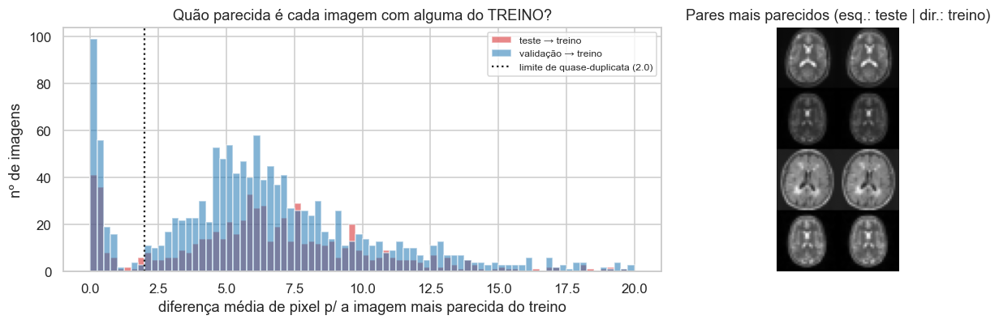

=> 101 imagens de TESTE (14.8%) têm quase-duplicata no TREINO: vazamento. Cada etapa reporta também o desempenho no TESTE LIMPO (sem elas).


In [3]:
EXT = (".jpg", ".jpeg", ".png", ".bmp")
tf_aval = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(), transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
DS = {s: datasets.ImageFolder(PASTA_DADOS / PASTA_S[s], tf_aval) for s in ("train", "val", "test")}
CLASSES = DS["val"].classes; NC = len(CLASSES)
assert CLASSES == DS["test"].classes == DS["train"].classes == meta["classes"], "As classes não batem!"
Y = {s: np.array(DS[s].targets) for s in DS}

cont = pd.DataFrame({NOME_S[s]: pd.Series(Y[s]).map(dict(enumerate(CLASSES))).value_counts() for s in DS}).loc[CLASSES]
cont.loc["TOTAL"] = cont.sum(); cont["total"] = cont.sum(axis=1); display(cont); salvar_tab(cont, "0_dataset.csv")
if PASTA_DADOS_Y.exists():
    rel = lambda r: sorted(str(p.relative_to(r)).replace("\\", "/") for p in Path(r).rglob("*") if p.suffix.lower() in EXT)
    print("Pastas CNN e YOLO contêm exatamente as mesmas imagens:", rel(PASTA_DADOS) == rel(PASTA_DADOS_Y))

CAM = {s: [p for p, _ in DS[s].samples] for s in DS}
md5 = {s: [hashlib.md5(Path(p).read_bytes()).hexdigest() for p in CAM[s]] for s in DS}
X32 = {s: np.stack([np.asarray(Image.open(p).convert("L").resize((32, 32), Image.BILINEAR), dtype=np.float32).ravel() for p in CAM[s]]) for s in DS}
NN, NNj, ND, linhas = {}, {}, {}, []
for a, b in (("test", "train"), ("val", "train"), ("test", "val")):
    D = cdist(X32[a], X32[b], "cityblock") / X32[a].shape[1]; NN[(a, b)], NNj[(a, b)] = D.min(1), D.argmin(1); ND[(a, b)] = NN[(a, b)] <= DUP_LIM
    rot_igual = np.mean([DS[a].targets[i] == DS[b].targets[NNj[(a, b)][i]] for i in np.where(ND[(a, b)])[0]]) if ND[(a, b)].any() else np.nan
    linhas.append({"Comparação": f"{NOME_S[a]} × {NOME_S[b]}", "Hash de arquivo idêntico": len(set(md5[a]) & set(md5[b])), "Quase-idênticas (dif. ≤ 0,5)": int((NN[(a, b)] <= 0.5).sum()),
                   f"Quase-duplicatas (dif. ≤ {DUP_LIM})": int(ND[(a, b)].sum()), f"% de {NOME_S[a]}": 100 * ND[(a, b)].mean(), "Rótulo igual ao do par?": rot_igual})
dup = pd.DataFrame(linhas); display(dup.round(3).style.hide(axis="index")); salvar_tab(dup, "0_vazamento.csv", index=False)
dup_teste_treino = int(ND[("test", "train")].sum())

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for k, c in ((("test", "train"), "#d62728"), (("val", "train"), "#1f77b4")):
    ax[0].hist(NN[k], bins=np.linspace(0, 20, 81), alpha=.55, color=c, label=f"{NOME_S[k[0]]} → {NOME_S[k[1]]}")
ax[0].axvline(DUP_LIM, color="k", ls=":", label=f"limite de quase-duplicata ({DUP_LIM})"); ax[0].set_xlabel("diferença média de pixel p/ a imagem mais parecida do treino"); ax[0].set_ylabel("nº de imagens")
ax[0].set_title("Quão parecida é cada imagem com alguma do TREINO?"); ax[0].legend(fontsize=8)
ordem = np.argsort(NN[("test", "train")])[:4]
ax[1].imshow(np.concatenate([np.concatenate([X32["test"][i].reshape(32, 32), X32["train"][NNj[("test", "train")][i]].reshape(32, 32)], 1) for i in ordem], 0), cmap="gray"); ax[1].axis("off")
ax[1].set_title("Pares mais parecidos (esq.: teste | dir.: treino)"); plt.tight_layout(); salvar_fig("0_vazamento.png")
print(f"=> {dup_teste_treino} imagens de TESTE ({100*dup_teste_treino/len(Y['test']):.1f}%) têm quase-duplicata no TREINO: vazamento. Cada etapa reporta também o desempenho no TESTE LIMPO (sem elas).")
LIMPO = {"test": ~(ND[("test", "train")] | ND[("test", "val")]), "val": ~ND[("val", "train")]}

## P.3 Carregar os modelos e gerar as probabilidades
Os dois modelos são avaliados **nas mesmas imagens, na mesma ordem**, guardando o *softmax* completo. Tudo o que vem depois (ROC, log-loss, calibração, estatística) parte dessas probabilidades.

In [4]:
def criar_modelo(nome, n):
    if nome == "efficientnet_b0":
        m = models.efficientnet_b0(weights=None); m.classifier[1] = nn.Linear(m.classifier[1].in_features, n)
    elif nome == "resnet50":
        m = models.resnet50(weights=None); m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, n))
    elif nome == "convnext_tiny":
        m = models.convnext_tiny(weights=None); m.classifier[2] = nn.Linear(m.classifier[2].in_features, n)
    else: raise ValueError(nome)
    return m
cnn = criar_modelo(MODELO, NC); cnn.load_state_dict(torch.load(PESO_CNN, map_location="cpu")); cnn = cnn.to(device).eval()
yolo = YOLO(str(PESO_YOLO))
idx_y = [next(k for k, v in yolo.names.items() if v == c) for c in CLASSES]   # ordem do YOLO -> ordem do ImageFolder
yolo_net = yolo.model.to(device).eval()
REDE = {NOME_Y: yolo_net, NOME_C: cnn}

@torch.no_grad()
def probs_cnn_ds(ds):
    dl = DataLoader(ds, batch_size=BATCH, shuffle=False, num_workers=NUM_WORKERS); ps = []
    for x, _ in dl: ps.append(torch.softmax(cnn(x.to(device)), 1).cpu().numpy())
    return np.concatenate(ps)
def probs_yolo_ds(ds):
    caminhos = [p for p, _ in ds.samples]; ps = []
    for i in range(0, len(caminhos), 64):
        for r in yolo.predict(caminhos[i:i+64], imgsz=IMG_SIZE, verbose=False, device=device.type): ps.append(r.probs.data.cpu().numpy()[idx_y])
    return np.array(ps)
def com_cache(chave, fn):
    f = BASE / "Validacoes" / "_compartilhado" / "cache" / f"{chave}.npy"
    if USAR_CACHE and f.exists(): return np.load(f)
    r = fn(); f.parent.mkdir(exist_ok=True); np.save(f, r); return r
sel = lambda p: int(Path(p).stat().st_mtime)
t0 = time.time(); PROB = {m: {} for m in MODELOS}
for s in SPLITS:
    PROB[NOME_C][s] = com_cache(f"cnn_{s}_{sel(PESO_CNN)}_{len(DS[s])}", lambda: probs_cnn_ds(DS[s]))
    PROB[NOME_Y][s] = com_cache(f"yolo_{s}_{sel(PESO_YOLO)}_{len(DS[s])}", lambda: probs_yolo_ds(DS[s]))
    print(f"  {NOME_S[s]:10s} ok ({len(DS[s])} imagens) — {time.time()-t0:.0f}s")
PRED = {m: {s: PROB[m][s].argmax(1) for s in SPLITS} for m in MODELOS}

ref = {(NOME_Y, "val"): 0.9709934592247009, (NOME_Y, "test"): 0.9794420003890991, (NOME_C, "val"): meta["melhor_acc_val"]}
for (m, s), v in ref.items():
    a = accuracy_score(Y[s], PRED[m][s]); print(f"  conferência {m:16s} {NOME_S[s]:10s} acc={a:.4f} | registrado no treino={v:.4f} | {'OK' if abs(a-v) < 2e-3 else 'DIFERE!'}")

  treino     ok (4819 imagens) — 0s
  validação  ok (1379 imagens) — 0s
  teste      ok (681 imagens) — 0s
  conferência YOLO11s-cls      validação  acc=0.9710 | registrado no treino=0.9710 | OK
  conferência YOLO11s-cls      teste      acc=0.9794 | registrado no treino=0.9794 | OK
  conferência EfficientNet-B0  validação  acc=0.9884 | registrado no treino=0.9884 | OK


## P.4 Funções auxiliares (métricas, perturbações, Grad-CAM, custo)

In [5]:
def ece(y, probs, bins=10):
    conf, ok = probs.max(1), (probs.argmax(1) == y).astype(float); e = 0.0
    for lo, hi in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        mk = (conf > lo) & (conf <= hi)
        if mk.any(): e += mk.mean() * abs(ok[mk].mean() - conf[mk].mean())
    return e
def brier(y, probs): return float(np.mean(np.sum((probs - np.eye(NC)[y]) ** 2, 1)))
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z * z / n; c = p + z * z / (2 * n); a = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)); return (c - a) / d, (c + a) / d
def perda_amostra(y, probs): return -np.log(np.clip(probs[np.arange(len(y)), y], 1e-12, 1))
ic = lambda v: np.percentile(v, [2.5, 97.5])

def metricas(y, probs):
    p = probs.argmax(1)
    return {"Acurácia (top-1)": accuracy_score(y, p), "Acurácia balanceada": balanced_accuracy_score(y, p),
            "Precisão macro": precision_score(y, p, average="macro"), "Recall macro": recall_score(y, p, average="macro"),
            "F1 macro": f1_score(y, p, average="macro"), "MCC": matthews_corrcoef(y, p), "Kappa": cohen_kappa_score(y, p),
            "AUC macro (OvR)": roc_auc_score(y, probs, multi_class="ovr"), "AP macro (PR)": average_precision_score(np.eye(NC)[y], probs, average="macro"),
            "Log-loss": log_loss(y, probs, labels=list(range(NC))), "Brier": brier(y, probs), "ECE": ece(y, probs),
            "Erros (nº)": int((p != y).sum()), "Imagens": len(y)}
def roc_macro(y, probs):
    Yb = np.eye(NC)[y]; fprs = np.unique(np.concatenate([roc_curve(Yb[:, i], probs[:, i])[0] for i in range(NC)]))
    tpr = np.mean([np.interp(fprs, *roc_curve(Yb[:, i], probs[:, i])[:2]) for i in range(NC)], axis=0); return fprs, tpr, auc(fprs, tpr)
SV = [s for s in ("val", "test") if s in SPLITS]

# ---------- perturbações (robustez) ----------
def p_ruido(sig):
    def f(im, r): a = np.asarray(im, dtype=np.float32) + r.normal(0, sig, (im.size[1], im.size[0], 3)); return Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))
    return f
def p_jpeg(q):
    def f(im, r): b = io.BytesIO(); im.save(b, "JPEG", quality=q); b.seek(0); return Image.open(b).convert("RGB")
    return f
def p_oclusao(frac):
    def f(im, r):
        w, h = im.size; s_ = int(w * frac); x0, y0 = int(r.integers(0, w - s_)), int(r.integers(0, h - s_)); o = im.copy(); o.paste((0, 0, 0), (x0, y0, x0 + s_, y0 + s_)); return o
    return f
PERT = {"original": lambda im, r: im, "ruído gaussiano σ=10": p_ruido(10), "ruído gaussiano σ=25": p_ruido(25),
        "desfoque (raio 2)": lambda im, r: im.filter(ImageFilter.GaussianBlur(2)), "desfoque (raio 4)": lambda im, r: im.filter(ImageFilter.GaussianBlur(4)),
        "brilho −30%": lambda im, r: ImageEnhance.Brightness(im).enhance(0.7), "brilho +30%": lambda im, r: ImageEnhance.Brightness(im).enhance(1.3),
        "contraste −40%": lambda im, r: ImageEnhance.Contrast(im).enhance(0.6), "JPEG q=20": p_jpeg(20),
        "rotação 10°": lambda im, r: im.rotate(10, fillcolor=(0, 0, 0)), "flip horizontal": lambda im, r: im.transpose(Image.FLIP_LEFT_RIGHT),
        "oclusão 25% da largura": p_oclusao(0.25)}
rng_r = np.random.default_rng(SEED); idx_rob = []
for i in range(NC):
    pool = np.where(Y["test"] == i)[0]; idx_rob += list(rng_r.choice(pool, min(len(pool), N_ROBUSTEZ // NC), replace=False))
idx_rob = np.array(sorted(idx_rob)); y_rob = Y["test"][idx_rob]; imgs0 = [Image.open(CAM["test"][i]).convert("RGB") for i in idx_rob]

@torch.no_grad()
def prever_pil(m, imgs):
    if m == NOME_C:
        out = []
        for i in range(0, len(imgs), 32): out.append(torch.softmax(cnn(torch.stack([tf_aval(im) for im in imgs[i:i+32]]).to(device)), 1).cpu().numpy())
        return np.concatenate(out)
    ps = []
    for i in range(0, len(imgs), 32):
        for r in yolo.predict(imgs[i:i+32], imgsz=IMG_SIZE, verbose=False, device=device.type): ps.append(r.probs.data.cpu().numpy()[idx_y])
    return np.array(ps)

# ---------- Grad-CAM ----------
def gradcam(net, camada, x, classe=None):
    ativ, grads = [], []
    def fh(mod, inp, out): ativ.append(out); out.register_hook(lambda g: grads.append(g))
    h = camada.register_forward_hook(fh)
    with torch.enable_grad():
        xx = x.clone().requires_grad_(True); net.zero_grad(); out = net(xx); out = out[0] if isinstance(out, (tuple, list)) else out
        c = int(out.argmax(1)) if classe is None else classe; out[0, c].backward()
    h.remove(); a, g = ativ[0].detach(), grads[0].detach(); cam = F.relu((g.mean((2, 3), keepdim=True) * a).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[0, 0]; cam = cam / (cam.max() + 1e-8); return cam.cpu().numpy(), c
GC = {NOME_C: (cnn, cnn.features[-1], lambda im: tf_aval(im).unsqueeze(0).to(device)),
      NOME_Y: (yolo_net, yolo_net.model[-2], lambda im: transforms.ToTensor()(im.resize((IMG_SIZE, IMG_SIZE))).unsqueeze(0).to(device))}

# ---------- custo computacional ----------
from torch.utils.flop_counter import FlopCounterMode
x1 = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=device)
def gflops(net):
    try:
        with torch.inference_mode(), FlopCounterMode(display=False) as fc: net(x1)
        return fc.get_total_flops() / 1e9
    except Exception as e: print("FLOPs indisponível:", e); return np.nan
def latencia(net, rep=30, aq=5):
    with torch.inference_mode():
        for _ in range(aq): net(x1)
        ts = []
        for _ in range(rep): sincronizar(); t = time.perf_counter(); net(x1); sincronizar(); ts.append((time.perf_counter() - t) * 1000)
    return np.array(ts)

# dicionários onde cada etapa guarda seus resultados (a Etapa 3 reutiliza)
R = {k: {} for k in ("met", "gap", "treino", "pc", "cal", "sel", "clin", "boot", "limpo", "rob", "efi", "det", "erros", "ck")}

---
# ETAPA 1 — Avaliação do modelo YOLO11s-cls
Todas as análises abaixo usam **apenas o YOLO**. As funções são definidas aqui e reaproveitadas na Etapa 2 para a CNN.

### 1.1 Métricas por conjunto (treino · validação · teste)
Acurácia, F1, MCC, kappa, AUC, AP, **log-loss**, Brier (qualidade das probabilidades), ECE (calibração) e nº de erros.

In [6]:
def tab_metricas(m):
    t = pd.DataFrame({NOME_S[s]: metricas(Y[s], PROB[m][s]) for s in SPLITS}); R["met"][m] = t
    print(f"=== {m} ==="); display(t.round(4)); salvar_tab(t, f"{PRE[m]}_01_metricas.csv"); return t
_ = tab_metricas(NOME_Y)

=== YOLO11s-cls ===


,treino,validação,teste
Acurácia (top-1),0.9994,0.9710,0.9794
Acurácia balanceada,0.9994,0.9703,0.9796
Precisão macro,0.9994,0.9707,0.9792
Recall macro,0.9994,0.9703,0.9796
F1 macro,0.9994,0.9703,0.9794
MCC,0.9992,0.9614,0.9726
Kappa,0.9992,0.9613,0.9726
AUC macro (OvR),1.0000,0.9966,0.9984
AP macro (PR),1.0000,0.9923,0.9959
Log-loss,0.0094,0.1218,0.0780


### 1.2 Curvas ROC e Precision-Recall
A **ROC** mostra, por classe (um-contra-todos), a taxa de acerto (TPR) contra a de falsos alarmes (FPR) ao variar o limiar; **AUC = 1** é separação perfeita. Como o modelo está perto de 1, mostramos a curva completa e um **zoom** no canto superior esquerdo. A curva **Precision-Recall** é mais exigente com classes desbalanceadas.

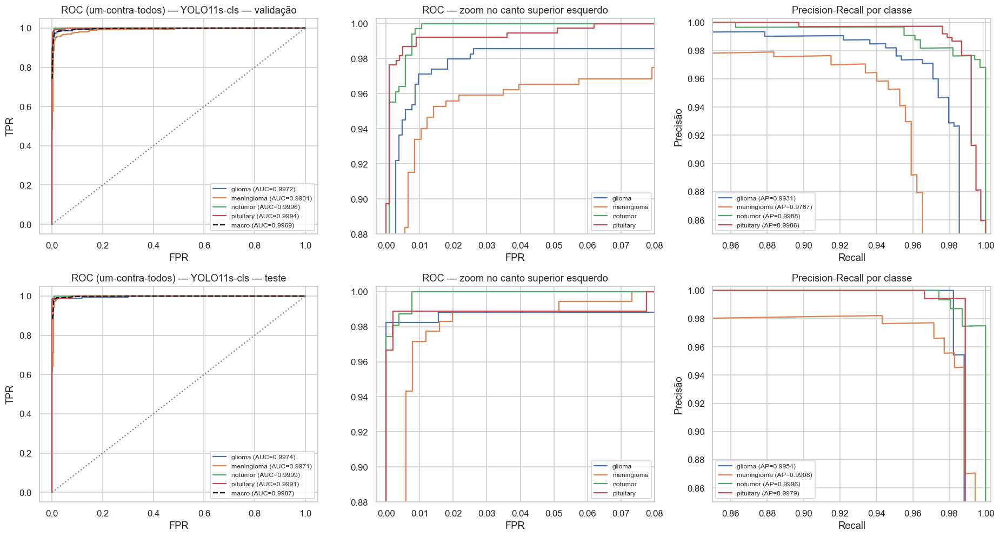

AP                AUC          
Conjunto      teste validação    teste validação
Classe                                          
glioma      0.99539   0.99313  0.99744   0.99717
meningioma  0.99077   0.97866  0.99709   0.99006
notumor     0.99955   0.99883  0.99987   0.99963
pituitary   0.99787   0.99863  0.99909   0.99944

In [7]:
def roc_pr(m):
    fig, ax = plt.subplots(len(SV), 3, figsize=(17, 4.6 * len(SV))); ax = np.atleast_2d(ax)
    for r, s in enumerate(SV):
        Yb = np.eye(NC)[Y[s]]; P = PROB[m][s]
        for i, c in enumerate(CLASSES):
            fpr, tpr, _ = roc_curve(Yb[:, i], P[:, i]); a_ = roc_auc_score(Yb[:, i], P[:, i])
            ax[r, 0].plot(fpr, tpr, label=f"{c} (AUC={a_:.4f})"); ax[r, 1].plot(fpr, tpr, label=c)
            pr_, rc_, _ = precision_recall_curve(Yb[:, i], P[:, i]); ax[r, 2].plot(rc_, pr_, label=f"{c} (AP={average_precision_score(Yb[:, i], P[:, i]):.4f})")
        fm, tm, am = roc_macro(Y[s], P); ax[r, 0].plot(fm, tm, "k--", lw=1.6, label=f"macro (AUC={am:.4f})"); ax[r, 0].plot([0, 1], [0, 1], ":", color="gray")
        ax[r, 0].set_title(f"ROC (um-contra-todos) — {m} — {NOME_S[s]}"); ax[r, 0].set_xlabel("FPR"); ax[r, 0].set_ylabel("TPR"); ax[r, 0].legend(fontsize=8, loc="lower right")
        ax[r, 1].set_xlim(-0.003, 0.08); ax[r, 1].set_ylim(0.88, 1.003); ax[r, 1].set_title("ROC — zoom no canto superior esquerdo"); ax[r, 1].set_xlabel("FPR"); ax[r, 1].legend(fontsize=8, loc="lower right")
        ax[r, 2].set_xlim(0.85, 1.003); ax[r, 2].set_ylim(0.85, 1.003); ax[r, 2].set_title("Precision-Recall por classe"); ax[r, 2].set_xlabel("Recall"); ax[r, 2].set_ylabel("Precisão"); ax[r, 2].legend(fontsize=8, loc="lower left")
    plt.tight_layout(); salvar_fig(f"{PRE[m]}_02_roc_pr.png")
    t = pd.DataFrame([{"Conjunto": NOME_S[s], "Classe": c, "AUC": roc_auc_score(Y[s] == i, PROB[m][s][:, i]), "AP": average_precision_score(Y[s] == i, PROB[m][s][:, i])} for s in SV for i, c in enumerate(CLASSES)])
    display(t.pivot_table(index="Classe", columns="Conjunto", values=["AUC", "AP"]).round(5)); salvar_tab(t, f"{PRE[m]}_02_auc_por_classe.csv", index=False)
roc_pr(NOME_Y)

### 1.3 Log-loss (entropia cruzada)
Acurácia só vê o *argmax*; o **log-loss** pune confiança errada (errar com 99% de certeza custa muito mais que errar com 55%). Vemos (a) o log-loss em treino/valid/teste, (b) por classe e (c) a distribuição da perda por imagem, para saber se o valor médio é dominado por poucos erros graves.

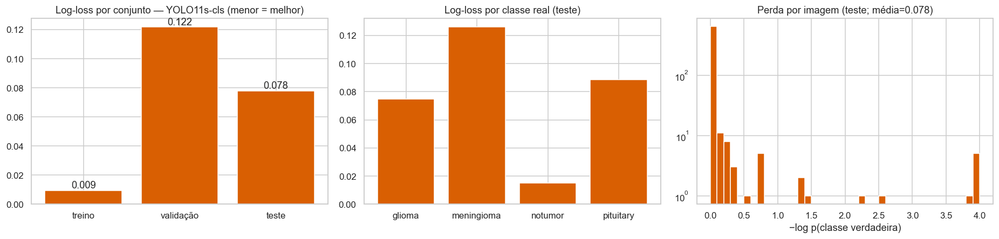

As 34 imagens com maior perda (5% do teste) respondem por 92.5% do log-loss total.


In [8]:
def logloss_m(m):
    ll = {NOME_S[s]: log_loss(Y[s], PROB[m][s], labels=list(range(NC))) for s in SPLITS}
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
    ax[0].bar(list(ll), list(ll.values()), color=COR[m]); ax[0].set_title(f"Log-loss por conjunto — {m} (menor = melhor)")
    for i, v in enumerate(ll.values()): ax[0].text(i, v, f"{v:.3f}", ha="center", va="bottom")
    l = perda_amostra(Y["test"], PROB[m]["test"]); llc = [l[Y["test"] == i].mean() for i in range(NC)]
    ax[1].bar(CLASSES, llc, color=COR[m]); ax[1].set_title("Log-loss por classe real (teste)")
    ax[2].hist(np.clip(l, 0, 4), bins=np.linspace(0, 4, 41), color=COR[m]); ax[2].set_yscale("log"); ax[2].set_title(f"Perda por imagem (teste; média={l.mean():.3f})"); ax[2].set_xlabel("−log p(classe verdadeira)")
    plt.tight_layout(); salvar_fig(f"{PRE[m]}_03_logloss.png")
    k = max(1, int(0.05 * len(l))); top = np.sort(l)[::-1]
    print(f"As {k} imagens com maior perda (5% do teste) respondem por {100*top[:k].sum()/l.sum():.1f}% do log-loss total.")
    salvar_tab(pd.DataFrame({"log-loss": ll}), f"{PRE[m]}_03_logloss.csv")
logloss_m(NOME_Y)

### 1.4 Acurácia treino × validação × teste — há variância alta?
Diagnóstico central de **viés vs. variância**:
- **treino ≫ valid** → *variância alta / overfitting*; **treino e valid baixos** → *viés alto / underfitting*;
- **valid ≈ teste** → a escolha do melhor *epoch* pelo valid não "vazou" para o teste.

As barras trazem **IC de Wilson 95%**. O treino é avaliado **sem augmentation** (modo inferência). À direita, a evolução época a época do gap.

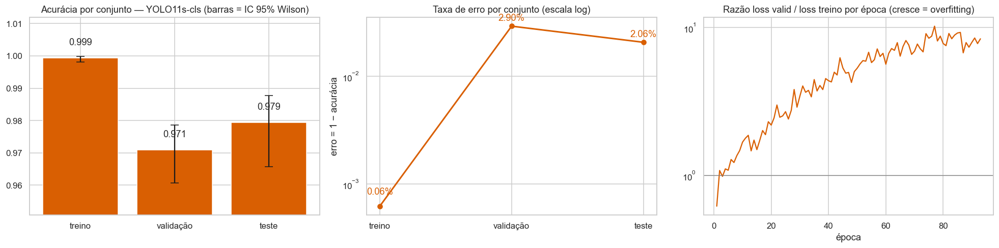

Gaps (p.p.): {'treino−valid': 2.84, 'valid−teste': -0.84, 'treino−teste': 1.99}
valid=0.9710 vs teste=0.9794: p-valor (2 proporções)=0.259 → compatível com ruído amostral
Diagnóstico: acc treino=0.9994 | gap treino−valid=2.84 p.p. → variância baixa; viés baixo.


In [9]:
def variancia(m):
    d = []
    for s in SPLITS:
        k = int((PRED[m][s] == Y[s]).sum()); n = len(Y[s]); lo, hi = wilson(k, n); d.append((NOME_S[s], k / n, lo, hi))
    d = pd.DataFrame(d, columns=["Conjunto", "Acurácia", "lo", "hi"]); salvar_tab(d, f"{PRE[m]}_04_acuracia_por_conjunto.csv", index=False)
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
    ax[0].bar(d["Conjunto"], d["Acurácia"], color=COR[m], yerr=[d["Acurácia"] - d["lo"], d["hi"] - d["Acurácia"]], capsize=5)
    for i, v in enumerate(d["Acurácia"]): ax[0].text(i, v + 0.004, f"{v:.3f}", ha="center")
    ax[0].set_ylim(max(0.9, d["lo"].min() - 0.01), 1.012); ax[0].set_title(f"Acurácia por conjunto — {m} (barras = IC 95% Wilson)")
    ax[1].plot(d["Conjunto"], 1 - d["Acurácia"], "o-", color=COR[m], lw=2); ax[1].set_yscale("log"); ax[1].set_ylabel("erro = 1 − acurácia")
    for i, v in enumerate(1 - d["Acurácia"]): ax[1].text(i, v * 1.12 + 1e-4, f"{100*v:.2f}%", ha="center", color=COR[m])
    ax[1].set_title("Taxa de erro por conjunto (escala log)")
    if m == NOME_C:
        h = hist_c; ax[2].plot(h["epoca"], h["acc_treino"], "--", color=COR[m], label="treino (com augmentation)"); ax[2].plot(h["epoca"], h["acc_val"], color=COR[m], label="validação")
        ax[2].fill_between(h["epoca"], h["acc_val"], h["acc_treino"], color=COR[m], alpha=.15); ax[2].set_ylim(0.6, 1.003); ax[2].set_title("Acurácia treino × valid por época"); ax[2].legend(loc="lower right")
    else:
        rr = hist_y["val/loss"] / hist_y["train/loss"]; ax[2].plot(hist_y["epoch"], rr, color=COR[m]); ax[2].axhline(1, color="gray", lw=.8); ax[2].set_yscale("log")
        ax[2].set_title("Razão loss valid / loss treino por época (cresce = overfitting)")
    ax[2].set_xlabel("época"); plt.tight_layout(); salvar_fig(f"{PRE[m]}_04_acuracia_treino_val_teste.png")
    a = {s: accuracy_score(Y[s], PRED[m][s]) for s in SPLITS}
    g = {"treino−valid": a["train"] - a["val"] if "train" in a else np.nan, "valid−teste": a["val"] - a["test"], "treino−teste": a["train"] - a["test"] if "train" in a else np.nan}
    R["gap"][m] = g; print("Gaps (p.p.):", {k: round(100 * v, 2) for k, v in g.items()})
    p1, n1, p2, n2 = a["val"], len(Y["val"]), a["test"], len(Y["test"]); pp = (p1 * n1 + p2 * n2) / (n1 + n2)
    z = (p1 - p2) / math.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2)); pv = 2 * (1 - norm.cdf(abs(z)))
    print(f"valid={p1:.4f} vs teste={p2:.4f}: p-valor (2 proporções)={pv:.3f} → {'diferença significativa' if pv < .05 else 'compatível com ruído amostral'}")
    if not np.isnan(g["treino−valid"]):
        dg = "VARIÂNCIA ALTA (overfitting)" if g["treino−valid"] > 0.05 else ("variância moderada" if g["treino−valid"] > CRIT["gap_treino_val_max"] else "variância baixa")
        print(f"Diagnóstico: acc treino={a['train']:.4f} | gap treino−valid={100*g['treino−valid']:.2f} p.p. → {dg}; {'VIÉS ALTO' if a['train'] < 0.90 else 'viés baixo'}.")
variancia(NOME_Y)

### 1.5 Loss de treino e taxa de aprendizado
Lemos o histórico real do treino (`results.csv` do YOLO, incluindo o **LR** gravado). O que olhar: loss de treino caindo suave (otimização estável), loss de validação estabilizando/subindo enquanto a de treino cai (início de overfitting) e a relação com a queda do LR (*warm-up* nas primeiras épocas, depois decaimento cosseno).

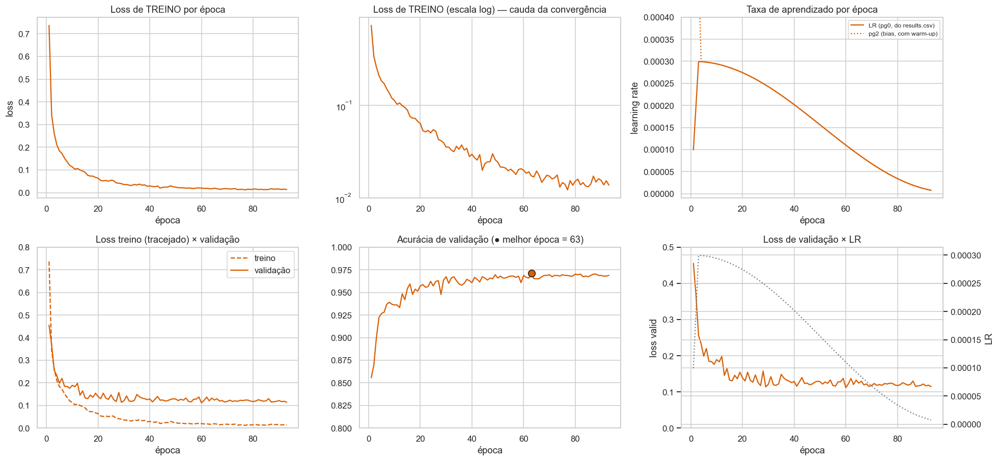

,YOLO11s-cls
Épocas,93
Melhor época,63
Menor loss de treino,0.0122
Loss de treino final,0.01374
Menor loss valid,0.11184
Época da menor loss valid,60
LR inicial,0.000099
LR final,0.000008
Tempo total (min),801.233333
Épocas c/ loss de treino subindo >30%,0


In [10]:
LR0 = 3e-4
TMAX = meta["epocas_treinadas"]   # ASSUNÇÃO (CNN): o cosine usou o nº de épocas realmente treinadas (a config EPOCAS não é gravada no meta)
hist_c["lr_reconstruido"] = [0.5 * LR0 * (1 + math.cos(math.pi * (e - 1) / TMAX)) for e in hist_c["epoca"]]

def treino_m(m):
    if m == NOME_Y: ep, tl, vl, va, lr = hist_y["epoch"], hist_y["train/loss"], hist_y["val/loss"], hist_y["metrics/accuracy_top1"], hist_y["lr/pg0"]; lrnome = "LR (pg0, do results.csv)"
    else: ep, tl, vl, va, lr = hist_c["epoca"], hist_c["loss_treino"], hist_c["loss_val"], hist_c["acc_val"], hist_c["lr_reconstruido"]; lrnome = f"LR (reconstruído: cosine, T_max={TMAX})"
    best = int(ep.iloc[va.reset_index(drop=True).idxmax()]); c = COR[m]
    fig, ax = plt.subplots(2, 3, figsize=(18, 8.4))
    ax[0, 0].plot(ep, tl, color=c); ax[0, 0].set_title("Loss de TREINO por época"); ax[0, 0].set_xlabel("época"); ax[0, 0].set_ylabel("loss")
    ax[0, 1].plot(ep, tl, color=c); ax[0, 1].set_yscale("log"); ax[0, 1].set_title("Loss de TREINO (escala log) — cauda da convergência"); ax[0, 1].set_xlabel("época")
    ax[0, 2].plot(ep, lr, color=c, label=lrnome)
    if m == NOME_Y: ax[0, 2].plot(ep, hist_y["lr/pg2"], color=c, ls=":", label="pg2 (bias, com warm-up)")
    ax[0, 2].set_title("Taxa de aprendizado por época"); ax[0, 2].set_xlabel("época"); ax[0, 2].set_ylabel("learning rate"); ax[0, 2].legend(fontsize=8)
    if m == NOME_Y: ax[0, 2].set_ylim(-1e-5, 4e-4)
    ax[1, 0].plot(ep, tl, "--", color=c, label="treino"); ax[1, 0].plot(ep, vl, color=c, label="validação"); ax[1, 0].set_ylim(0, 0.8); ax[1, 0].set_title("Loss treino (tracejado) × validação"); ax[1, 0].set_xlabel("época"); ax[1, 0].legend()
    ax[1, 1].plot(ep, va, color=c); ax[1, 1].scatter([best], [va.max()], s=80, color=c, edgecolor="k", zorder=5); ax[1, 1].set_ylim(0.8, 1.0)
    ax[1, 1].set_title(f"Acurácia de validação (● melhor época = {best})"); ax[1, 1].set_xlabel("época")
    a2 = ax[1, 2]; a3 = a2.twinx(); a2.plot(ep, vl, color=c); a3.plot(ep, lr, color="gray", ls=":"); a2.set_ylim(0, 0.5); a2.set_xlabel("época"); a2.set_ylabel("loss valid"); a3.set_ylabel("LR"); a2.set_title("Loss de validação × LR")
    plt.tight_layout(); salvar_fig(f"{PRE[m]}_05_treino_loss_lr.png")
    tempo = hist_y["time"].iloc[-1] / 60 if m == NOME_Y else meta["tempo_treino_min"]
    res = {"Épocas": len(ep), "Melhor época": best, "Menor loss de treino": tl.min(), "Loss de treino final": tl.iloc[-1], "Menor loss valid": vl.min(),
           "Época da menor loss valid": int(ep.iloc[vl.reset_index(drop=True).idxmin()]), "LR inicial": lr.iloc[0], "LR final": lr.iloc[-1], "Tempo total (min)": tempo,
           "Épocas c/ loss de treino subindo >30%": int((tl.pct_change() > 0.30).sum()),
           "Parou por early stopping": (len(hist_y) < args_y["epochs"]) if m == NOME_Y else "n/d (config do treino não gravada)"}
    R["treino"][m] = res; display(pd.Series(res, name=m).to_frame()); salvar_tab(pd.Series(res, name=m).to_frame(), f"{PRE[m]}_05_resumo_treino.csv")
treino_m(NOME_Y)

### 1.6 Matrizes de confusão e métricas por classe

--- YOLO11s-cls — validação
               precision    recall  f1-score   support

      glioma     0.9443    0.9798    0.9617       346
  meningioma     0.9674    0.9340    0.9504       318
     notumor     0.9765    0.9910    0.9837       335
   pituitary     0.9946    0.9763    0.9854       380

    accuracy                         0.9710      1379
   macro avg     0.9707    0.9703    0.9703      1379
weighted avg     0.9713    0.9710    0.9710      1379

--- YOLO11s-cls — teste
               precision    recall  f1-score   support

      glioma     0.9709    0.9824    0.9766       170
  meningioma     0.9769    0.9602    0.9685       176
     notumor     0.9747    0.9872    0.9809       156
   pituitary     0.9944    0.9888    0.9916       179

    accuracy                         0.9794       681
   macro avg     0.9792    0.9796    0.9794       681
weighted avg     0.9795    0.9794    0.9794       681



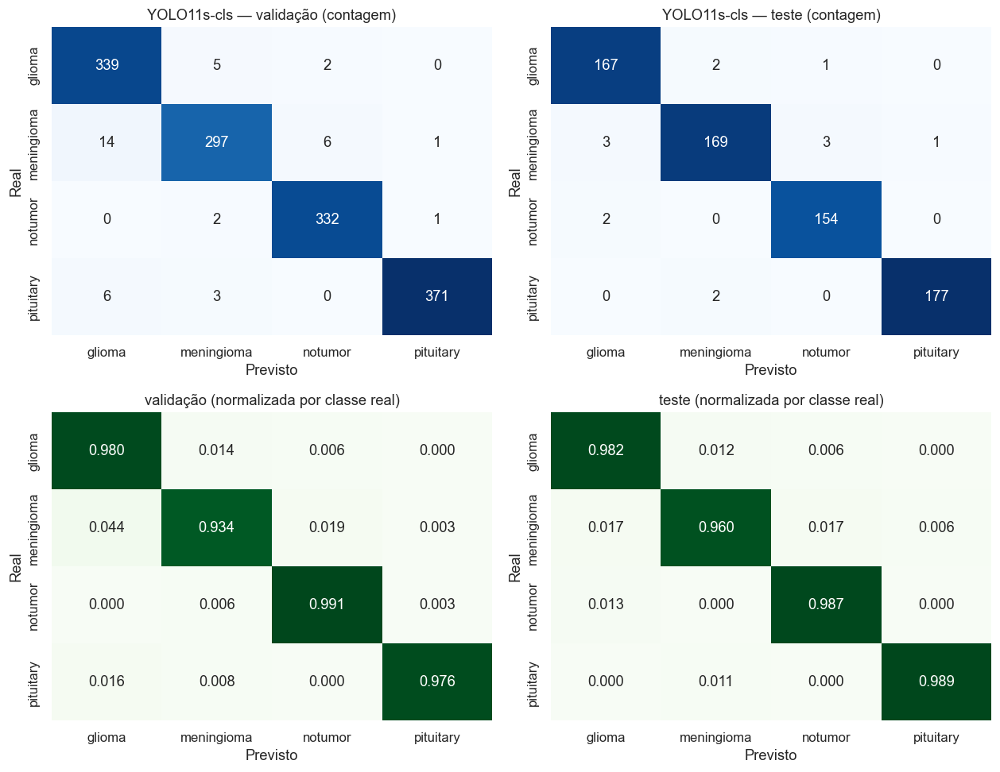

Confusões mais comuns no teste (real → previsto): meningioma→glioma (3); meningioma→notumor (3); glioma→meningioma (2); notumor→glioma (2)


In [11]:
def confusao_m(m):
    fig, ax = plt.subplots(2, len(SV), figsize=(5.8 * len(SV), 9)); ax = np.atleast_2d(ax).reshape(2, len(SV)); linhas = []
    for j, s in enumerate(SV):
        cm = confusion_matrix(Y[s], PRED[m][s]); cmn = cm / cm.sum(1, keepdims=True)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0, j], cbar=False); ax[0, j].set_title(f"{m} — {NOME_S[s]} (contagem)")
        sns.heatmap(cmn, annot=True, fmt=".3f", cmap="Greens", vmin=0, vmax=1, xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1, j], cbar=False); ax[1, j].set_title(f"{NOME_S[s]} (normalizada por classe real)")
        for a in ax[:, j]: a.set_xlabel("Previsto"); a.set_ylabel("Real")
        print(f"--- {m} — {NOME_S[s]}\n", classification_report(Y[s], PRED[m][s], target_names=CLASSES, digits=4))
        pr, rc, f1 = (f(Y[s], PRED[m][s], average=None) for f in (precision_score, recall_score, f1_score))
        for i, c in enumerate(CLASSES): linhas.append(dict(Conjunto=NOME_S[s], Classe=c, Precisão=pr[i], Recall=rc[i], F1=f1[i], Suporte=int((Y[s] == i).sum())))
    plt.tight_layout(); salvar_fig(f"{PRE[m]}_06_confusao.png"); R["pc"][m] = pd.DataFrame(linhas); salvar_tab(R["pc"][m], f"{PRE[m]}_06_por_classe.csv", index=False)
    cm = confusion_matrix(Y["test"], PRED[m]["test"]); np.fill_diagonal(cm, 0)
    pares = sorted([(CLASSES[i], CLASSES[j], int(cm[i, j])) for i in range(NC) for j in range(NC) if cm[i, j]], key=lambda t: -t[2])[:4]
    print("Confusões mais comuns no teste (real → previsto): " + "; ".join(f"{a}→{b} ({n})" for a, b, n in pares))
confusao_m(NOME_Y)

### 1.7 Calibração e predição seletiva
Um bom classificador médico precisa **saber quando não sabe**. Medimos se a confiança bate com a taxa real de acerto (**confiabilidade, ECE, Brier**) e o que acontece se o sistema **abstiver** nas previsões menos confiantes e as encaminhar para revisão humana (**acurácia × cobertura**).

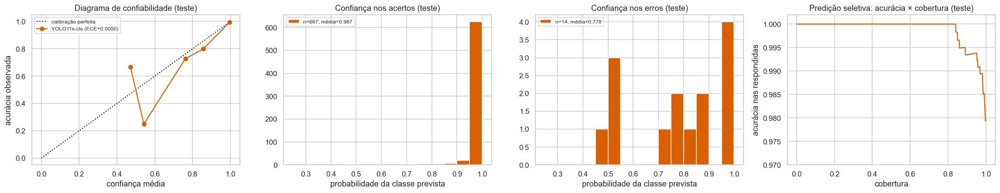

Limiar de confiança,Cobertura,Acurácia nas respondidas,Encaminhadas p/ revisão,Erros que escapam
0.500000,0.995600,0.980800,3,13
0.700000,0.989700,0.985200,7,10
0.800000,0.973600,0.989400,18,7
0.900000,0.951500,0.993800,33,4
0.950000,0.923600,0.993600,52,4
0.990000,0.838500,1.000000,110,0


{'ECE': np.float64(0.0049914936049569435), 'Brier': 0.032380638844441666, 'Confiança média (acertos)': np.float32(0.98701626), 'Confiança média (erros)': np.float32(0.77772707)}


In [12]:
def calibracao_m(m):
    s = "test"; P = PROB[m][s]; conf, ok = P.max(1), PRED[m][s] == Y[s]; bins = np.linspace(0, 1, 11); c = COR[m]
    fig, ax = plt.subplots(1, 4, figsize=(21, 4.2)); ax[0].plot([0, 1], [0, 1], "k:", label="calibração perfeita"); xs, ys = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mk = (conf > lo) & (conf <= hi)
        if mk.sum() >= 3: xs.append(conf[mk].mean()); ys.append(ok[mk].mean())
    ax[0].plot(xs, ys, "o-", color=c, label=f"{m} (ECE={ece(Y[s], P):.4f})"); ax[0].set_title("Diagrama de confiabilidade (teste)"); ax[0].set_xlabel("confiança média"); ax[0].set_ylabel("acurácia observada"); ax[0].legend(fontsize=8)
    for a, tipo, v in ((ax[1], "acertos", conf[ok]), (ax[2], "erros", conf[~ok])):
        if len(v): a.hist(v, bins=np.linspace(0.25, 1, 16), color=c, label=f"n={len(v)}, média={v.mean():.3f}"); a.legend(fontsize=8)
        a.set_title(f"Confiança nos {tipo} (teste)"); a.set_xlabel("probabilidade da classe prevista")
    o = np.argsort(-conf); cov = np.arange(1, len(o) + 1) / len(o); accs = np.cumsum(ok[o]) / np.arange(1, len(o) + 1)
    ax[3].plot(cov, accs, color=c); ax[3].set_ylim(0.97, 1.002); ax[3].set_title("Predição seletiva: acurácia × cobertura (teste)"); ax[3].set_xlabel("cobertura"); ax[3].set_ylabel("acurácia nas respondidas")
    plt.tight_layout(); salvar_fig(f"{PRE[m]}_07_calibracao.png")
    linhas = [{"Limiar de confiança": t, "Cobertura": (conf >= t).mean(), "Acurácia nas respondidas": ok[conf >= t].mean() if (conf >= t).any() else np.nan,
               "Encaminhadas p/ revisão": int((conf < t).sum()), "Erros que escapam": int((~ok & (conf >= t)).sum())} for t in (0.5, 0.7, 0.8, 0.9, 0.95, 0.99)]
    R["sel"][m] = pd.DataFrame(linhas); display(R["sel"][m].round(4).style.hide(axis="index")); salvar_tab(R["sel"][m], f"{PRE[m]}_07_predicao_seletiva.csv", index=False)
    R["cal"][m] = {"ECE": ece(Y[s], P), "Brier": brier(Y[s], P), "Confiança média (acertos)": conf[ok].mean(), "Confiança média (erros)": conf[~ok].mean() if (~ok).any() else np.nan}; print(R["cal"][m])
calibracao_m(NOME_Y)

### 1.8 Visão clínica: tumor × sem tumor
Nem todo erro pesa igual: o pior é o **falso negativo** (tumor passando como `notumor`). Colapsamos em *tumor* (glioma, meningioma, pituitary) × *sem tumor* e medimos sensibilidade/especificidade, ROC binária (P(tumor) = 1 − P(notumor)) e quanta especificidade se perde para exigir sensibilidade ≥ 99,5%.

Conjunto,Sensibilidade,Especificidade,VPP,VPN,Falsos negativos,Falsos positivos,AUC binária,"Especificidade c/ sens ≥ 99,5%",Acc. do tipo (só tumores)
validação,0.992300,0.991000,0.997100,0.976500,8,3,0.999600,0.964200,0.964600
teste,0.992400,0.987200,0.996200,0.974700,4,2,0.999900,0.987200,0.977100


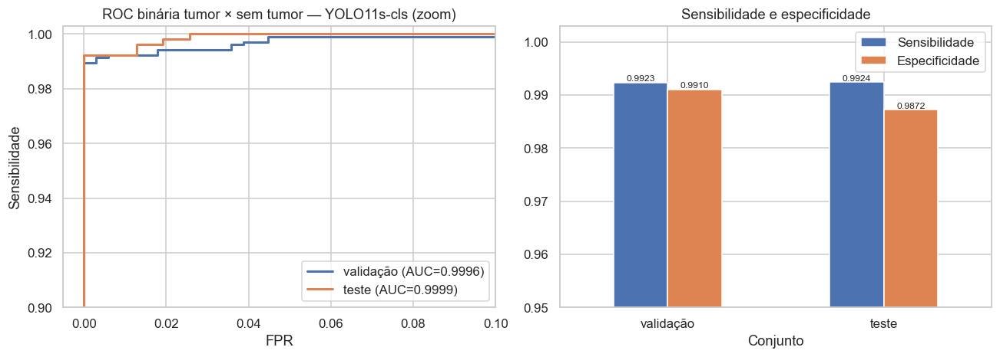

In [13]:
i_nt = CLASSES.index("notumor")
def clinica_m(m):
    linhas = []; fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
    for s in SV:
        yt, pt = Y[s] != i_nt, PRED[m][s] != i_nt; tp, fn, tn, fp = (yt & pt).sum(), (yt & ~pt).sum(), (~yt & ~pt).sum(), (~yt & pt).sum()
        score = 1 - PROB[m][s][:, i_nt]; fpr, tpr, _ = roc_curve(yt, score); okt = tpr >= 0.995
        linhas.append({"Conjunto": NOME_S[s], "Sensibilidade": tp / (tp + fn), "Especificidade": tn / (tn + fp), "VPP": tp / (tp + fp), "VPN": tn / (tn + fn), "Falsos negativos": int(fn), "Falsos positivos": int(fp),
                       "AUC binária": roc_auc_score(yt, score), "Especificidade c/ sens ≥ 99,5%": 1 - fpr[okt][0] if okt.any() else np.nan, "Acc. do tipo (só tumores)": accuracy_score(Y[s][yt], PRED[m][s][yt])})
        ax[0].plot(fpr, tpr, lw=2, label=f"{NOME_S[s]} (AUC={linhas[-1]['AUC binária']:.4f})")
    ax[0].set_xlim(-0.005, 0.1); ax[0].set_ylim(0.9, 1.003); ax[0].set_title(f"ROC binária tumor × sem tumor — {m} (zoom)"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("Sensibilidade"); ax[0].legend(loc="lower right")
    d = pd.DataFrame(linhas); R["clin"][m] = d; display(d.round(4).style.hide(axis="index")); salvar_tab(d, f"{PRE[m]}_08_visao_clinica.csv", index=False)
    d.set_index("Conjunto")[["Sensibilidade", "Especificidade"]].plot.bar(ax=ax[1], rot=0, color=["#4c72b0", "#dd8452"]); ax[1].set_ylim(0.95, 1.003); ax[1].set_title("Sensibilidade e especificidade")
    for cc in ax[1].containers: ax[1].bar_label(cc, fmt="%.4f", fontsize=8)
    plt.tight_layout(); salvar_fig(f"{PRE[m]}_08_visao_clinica.png")
clinica_m(NOME_Y)

### 1.9 Intervalos de confiança (bootstrap) e teste limpo (sem vazamento)
Com ~700 imagens, 1–2 erros mudam a 2ª casa decimal. O **bootstrap** dá IC 95% para acurácia, F1 e log-loss. O **teste limpo** remove as imagens com quase-duplicata no treino/valid (seção P.2): se o desempenho cai, a acurácia "oficial" estava inflada.

Conjunto,Métrica,Média,IC95% inf,IC95% sup
validação,Acurácia,0.970800,0.961600,0.979700
validação,F1 macro,0.970100,0.961000,0.979100
validação,Log-loss,0.122800,0.082500,0.168000
teste,Acurácia,0.979800,0.969200,0.989700
teste,F1 macro,0.979700,0.969300,0.989800
teste,Log-loss,0.077000,0.040100,0.119300


Conjunto,Subconjunto,n,Acurácia,IC95 inf,IC95 sup,Erros,Log-loss
validação,completo,1379,0.971000,0.960700,0.978600,40,0.121800
validação,limpo (sem quase-duplicata),1180,0.967800,0.956100,0.976400,38,0.133800
validação,só com quase-duplicata,199,0.989900,0.964100,0.997200,2,0.050600
teste,completo,681,0.979400,0.965800,0.987700,14,0.078000
teste,limpo (sem quase-duplicata),570,0.977200,0.961400,0.986600,13,0.090700
teste,só com quase-duplicata,111,0.991000,0.950700,0.998400,1,0.012700


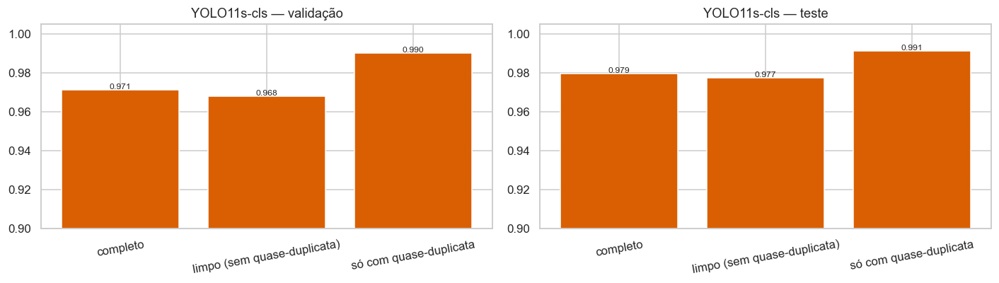

In [14]:
def boot_m(m, n=N_BOOT):
    rng = np.random.default_rng(SEED); out = {}   # mesma semente nos dois modelos => mesmas reamostragens (permite diferença pareada na Etapa 3)
    for s in SV:
        N = len(Y[s]); acc_, f1_, ll_ = [], [], []
        for _ in range(n):
            i = rng.integers(0, N, N); acc_.append((PRED[m][s][i] == Y[s][i]).mean()); f1_.append(f1_score(Y[s][i], PRED[m][s][i], average="macro")); ll_.append(perda_amostra(Y[s][i], PROB[m][s][i]).mean())
        out[s] = {"acc": np.array(acc_), "f1": np.array(f1_), "ll": np.array(ll_)}
    R["boot"][m] = out
    t = pd.DataFrame([{"Conjunto": NOME_S[s], "Métrica": nm, "Média": out[s][k].mean(), "IC95% inf": ic(out[s][k])[0], "IC95% sup": ic(out[s][k])[1]} for s in SV for k, nm in (("acc", "Acurácia"), ("f1", "F1 macro"), ("ll", "Log-loss"))])
    display(t.round(4).style.hide(axis="index")); salvar_tab(t, f"{PRE[m]}_09_bootstrap.csv", index=False)

def limpo_m(m):
    linhas = []
    for s in SV:
        for nome, mk in (("completo", np.ones(len(Y[s]), bool)), ("limpo (sem quase-duplicata)", LIMPO[s]), ("só com quase-duplicata", ~LIMPO[s])):
            k, n = int((PRED[m][s][mk] == Y[s][mk]).sum()), int(mk.sum()); lo, hi = wilson(k, n)
            linhas.append({"Conjunto": NOME_S[s], "Subconjunto": nome, "n": n, "Acurácia": k / n, "IC95 inf": lo, "IC95 sup": hi, "Erros": n - k, "Log-loss": log_loss(Y[s][mk], PROB[m][s][mk], labels=list(range(NC)))})
    d = pd.DataFrame(linhas); R["limpo"][m] = d; display(d.round(4).style.hide(axis="index")); salvar_tab(d, f"{PRE[m]}_09_teste_limpo.csv", index=False)
    fig, ax = plt.subplots(1, len(SV), figsize=(6.5 * len(SV), 3.8)); ax = np.atleast_1d(ax)
    for a, s in zip(ax, SV):
        x = d[d["Conjunto"] == NOME_S[s]]; a.bar(x["Subconjunto"], x["Acurácia"], color=COR[m]); a.set_ylim(0.9, 1.005); a.set_title(f"{m} — {NOME_S[s]}"); a.tick_params(axis="x", labelrotation=10)
        for i, v in enumerate(x["Acurácia"]): a.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    plt.tight_layout(); salvar_fig(f"{PRE[m]}_09_teste_limpo.png")
boot_m(NOME_Y); limpo_m(NOME_Y)

### 1.10 Robustez a perturbações
Imagens reais de RM variam (ruído, desfoque, brilho, compressão, posicionamento). Aplicamos perturbações controladas a uma amostra **estratificada** do teste (a mesma, com a mesma semente, nos dois modelos) e medimos a queda de acurácia. São perturbações sintéticas: indicam sensibilidade, não substituem validação em dados de outro hospital/scanner.

  original                   acc=0.975 (8s)


  ruído gaussiano σ=10       acc=0.767 (18s)


  ruído gaussiano σ=25       acc=0.400 (27s)


  desfoque (raio 2)          acc=0.667 (36s)


  desfoque (raio 4)          acc=0.250 (44s)


  brilho −30%                acc=0.983 (53s)


... (3 outputs left out)

  rotação 10°                acc=0.917 (82s)


  flip horizontal            acc=0.975 (90s)


  oclusão 25% da largura     acc=0.983 (96s)


,Acurácia,Log-loss
original,0.9750,0.1138
ruído gaussiano σ=10,0.7667,0.9188
ruído gaussiano σ=25,0.4000,3.6748
desfoque (raio 2),0.6667,1.2711
desfoque (raio 4),0.2500,8.2588
brilho −30%,0.9833,0.0887
brilho +30%,0.9667,0.1279
contraste −40%,0.9833,0.0876
JPEG q=20,0.5833,1.5021
rotação 10°,0.9167,0.2681


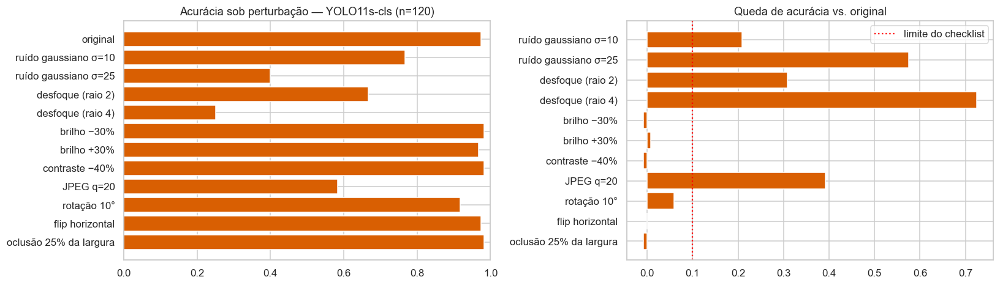

Queda média: 20.5 p.p.


In [15]:
def robustez_m(m):
    t0 = time.time(); res = {}
    for nome, f in PERT.items():
        r = np.random.default_rng(SEED); p = prever_pil(m, [f(im, r) for im in imgs0])
        res[nome] = (accuracy_score(y_rob, p.argmax(1)), log_loss(y_rob, p, labels=list(range(NC)))); print(f"  {nome:26s} acc={res[nome][0]:.3f} ({time.time()-t0:.0f}s)")
    R["rob"][m] = res; d = pd.DataFrame(res, index=["Acurácia", "Log-loss"]).T; display(d.round(4)); salvar_tab(d, f"{PRE[m]}_10_robustez.csv")
    queda = {n: res["original"][0] - res[n][0] for n in res if n != "original"}
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.4)); ax[0].barh(list(res), [v[0] for v in res.values()], color=COR[m]); ax[0].set_xlim(0, 1); ax[0].set_title(f"Acurácia sob perturbação — {m} (n={len(y_rob)})"); ax[0].invert_yaxis()
    ax[1].barh(list(queda), list(queda.values()), color=COR[m]); ax[1].axvline(CRIT["queda_robustez_max"], color="red", ls=":", label="limite do checklist"); ax[1].legend(); ax[1].set_title("Queda de acurácia vs. original"); ax[1].invert_yaxis()
    plt.tight_layout(); salvar_fig(f"{PRE[m]}_10_robustez.png"); print(f"Queda média: {100*np.mean(list(queda.values())):.1f} p.p.")
robustez_m(NOME_Y)

### 1.11 Grad-CAM e análise de erros
Mapas de ativação por gradiente mostram as regiões que mais influenciaram a decisão (esperamos foco na região da lesão/anatomia, não em bordas ou artefatos). Mostramos as imagens que **este modelo errou** e alguns acertos. É uma leitura qualitativa — não prova causalidade.

YOLO11s-cls: 14 erros no teste


,Arquivo,Real,Previsto,Confiança,Quase-duplicata no treino?
0,Te-gl_62_jpg.rf.e5510a0f35d1fd15d06d9a14cacfa3...,glioma,notumor,0.759,False
1,Te-gl_91_jpg.rf.a96f97376f7996206becc54f4d2d22...,glioma,meningioma,0.745,False
2,Tr-gl_987_jpg.rf.be57035d7df07075c03d166f1106e...,glioma,meningioma,0.983,False
3,Tr-me_1059_jpg.rf.2c6d37e0f90724baf37c99095ad3...,meningioma,glioma,0.756,False
4,Tr-me_1110_jpg.rf.bd2e6b251286a3e461ee93767aae...,meningioma,notumor,0.549,True
5,Tr-me_154_jpg.rf.b8aaba76d406f4f2d0750adf76a86...,meningioma,notumor,0.986,False
6,Tr-me_239_jpg.rf.8298adfe4e358f3bad6ecbff3a197...,meningioma,notumor,0.826,False
7,Tr-me_541_jpg.rf.ff3001e3f67189b5d3f16efb07b5e...,meningioma,glioma,0.892,False
8,Tr-me_807_jpg.rf.4180ce45eea266f1931ffe6c262fa...,meningioma,glioma,0.546,False
9,Tr-me_964_jpg.rf.6d728af1f74ceef073eb6acf88f7c...,meningioma,pituitary,0.886,False


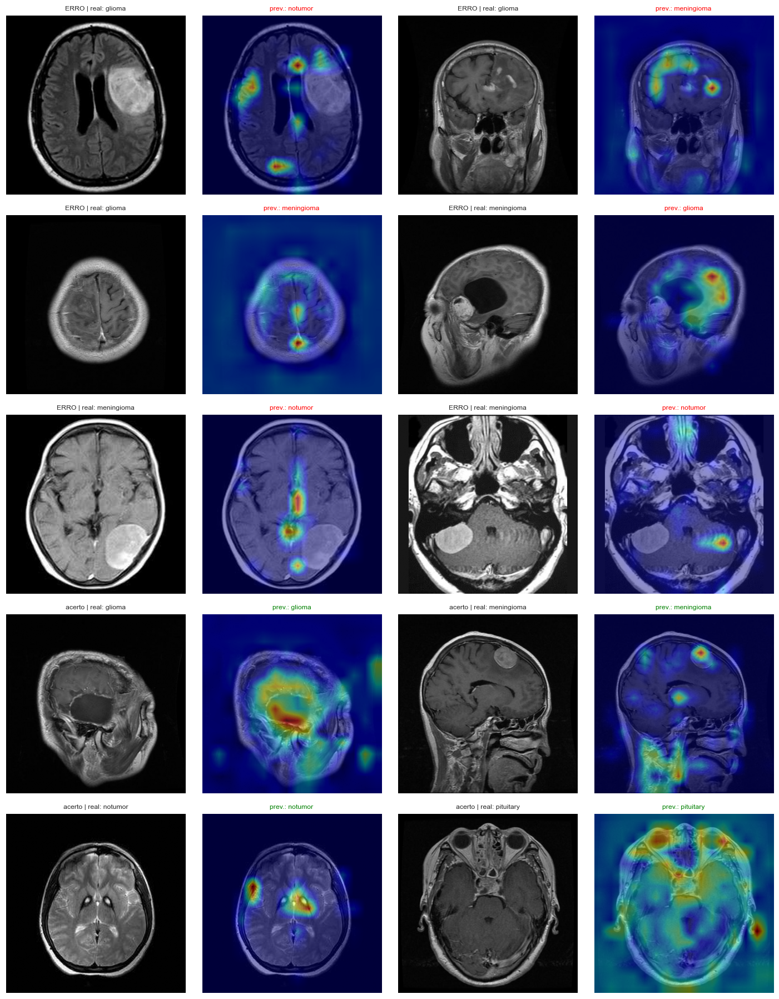

In [16]:
def erros_gradcam_m(m):
    err = np.where(PRED[m]["test"] != Y["test"])[0]
    linhas = [{"Arquivo": Path(CAM["test"][i]).name, "Real": CLASSES[Y["test"][i]], "Previsto": CLASSES[PRED[m]["test"][i]], "Confiança": PROB[m]["test"][i].max(),
               "Quase-duplicata no treino?": bool(ND[("test", "train")][i])} for i in err]
    d = pd.DataFrame(linhas); R["erros"][m] = d; salvar_tab(d, f"{PRE[m]}_11_erros_teste.csv", index=False); print(f"{m}: {len(err)} erros no teste"); display(d.round(3))
    rng2 = np.random.default_rng(SEED); corretos = [int(rng2.choice(np.where((Y["test"] == c) & (PRED[m]["test"] == c))[0])) for c in range(NC)]
    sel_idx = list(err[:N_GRADCAM]) + corretos; net, camada, tf = GC[m]
    try:
        fig, ax = plt.subplots(int(np.ceil(len(sel_idx) / 2)), 4, figsize=(13, 3.3 * int(np.ceil(len(sel_idx) / 2)))); ax = ax.reshape(-1, 4)
        for a in ax.ravel(): a.axis("off")
        for k, i in enumerate(sel_idx):
            r_, c0 = k // 2, (k % 2) * 2; im = Image.open(CAM["test"][i]).convert("RGB"); real = CLASSES[Y["test"][i]]; mapa, c = gradcam(net, camada, tf(im))
            ax[r_, c0].imshow(im.convert("L"), cmap="gray"); ax[r_, c0].set_title(f"{'ERRO' if i in err else 'acerto'} | real: {real}", fontsize=8)
            ax[r_, c0 + 1].imshow(im.convert("L"), cmap="gray"); ax[r_, c0 + 1].imshow(mapa, cmap="jet", alpha=.45); ax[r_, c0 + 1].set_title(f"prev.: {CLASSES[c]}", fontsize=8, color="green" if CLASSES[c] == real else "red")
        plt.tight_layout(); salvar_fig(f"{PRE[m]}_11_gradcam.png")
    except Exception as e: print("Grad-CAM não pôde ser gerado:", type(e).__name__, str(e)[:300])
erros_gradcam_m(NOME_Y)

### 1.12 Eficiência, reprodutibilidade e checklist de aprovação do YOLO
Custo (parâmetros, GFLOPs, latência) e **determinismo** (mesma imagem ⇒ mesma probabilidade). Depois, o **checklist**: cada critério vem de `CRIT` (metas do grupo; ✅ atende, ❌ não atende; desempenho medido no **teste**).

In [17]:
def eficiencia_m(m):
    net = REDE[m]; lt = latencia(net); a, b = prever_pil(m, imgs0[:32]), prever_pil(m, imgs0[:32])
    R["efi"][m] = {"Parâmetros (M)": sum(p.numel() for p in net.parameters()) / 1e6, "GFLOPs/imagem": gflops(net), "Peso em disco (MB)": (PESO_YOLO if m == NOME_Y else PESO_CNN).stat().st_size / 1e6,
                   "Latência mediana (ms)": float(np.median(lt)), "Latência p95 (ms)": float(np.percentile(lt, 95))}
    R["det"][m] = float(np.abs(a - b).max()); display(pd.Series(R["efi"][m], name=m).round(3).to_frame()); print("Determinismo (dif. máx. entre 2 execuções; 0 = determinístico):", R["det"][m])

def checklist_m(m):
    cv = lambda k: R["clin"][m][R["clin"][m]["Conjunto"] == "teste"][k].iloc[0]; P, y = PROB[m]["test"], Y["test"]
    acc_t = accuracy_score(y, PRED[m]["test"]); _l = R["limpo"][m]; acc_l = _l[(_l["Conjunto"] == "teste") & (_l["Subconjunto"].str.startswith("limpo"))]["Acurácia"].iloc[0]
    rec = recall_score(y, PRED[m]["test"], average=None).min(); auc_t = roc_auc_score(y, P, multi_class="ovr"); ll_t = log_loss(y, P, labels=list(range(NC))); e_t = ece(y, P)
    g1, g2 = R["gap"][m]["treino−valid"], abs(R["gap"][m]["valid−teste"]); queda = np.mean([R["rob"][m]["original"][0] - v[0] for k, v in R["rob"][m].items() if k != "original"])
    R["queda"] = R.get("queda", {}); R["queda"][m] = queda; R["acc_limpo"] = R.get("acc_limpo", {}); R["acc_limpo"][m] = acc_l
    L = [("Acurácia no teste", acc_t, f"≥ {CRIT['acc_teste_min']}", acc_t >= CRIT["acc_teste_min"]),
         ("Acurácia no teste LIMPO (sem quase-duplicatas)", acc_l, f"≥ {CRIT['acc_teste_min']}", acc_l >= CRIT["acc_teste_min"]),
         ("Menor recall entre as classes (teste)", rec, f"≥ {CRIT['recall_classe_min']}", rec >= CRIT["recall_classe_min"]),
         ("Sensibilidade p/ tumor (teste)", cv("Sensibilidade"), f"≥ {CRIT['sens_tumor_min']}", cv("Sensibilidade") >= CRIT["sens_tumor_min"]),
         ("AUC macro (teste)", auc_t, f"≥ {CRIT['auc_min']}", auc_t >= CRIT["auc_min"]), ("Log-loss (teste)", ll_t, f"≤ {CRIT['logloss_max']}", ll_t <= CRIT["logloss_max"]),
         ("ECE — calibração (teste)", e_t, f"≤ {CRIT['ece_max']}", e_t <= CRIT["ece_max"]),
         ("Gap treino − valid (variância)", g1, f"≤ {CRIT['gap_treino_val_max']}", (g1 <= CRIT["gap_treino_val_max"]) if not np.isnan(g1) else None),
         ("|Gap valid − teste|", g2, f"≤ {CRIT['gap_val_teste_max']}", g2 <= CRIT["gap_val_teste_max"]),
         ("Queda média de acurácia sob perturbação", queda, f"≤ {CRIT['queda_robustez_max']}", queda <= CRIT["queda_robustez_max"]),
         ("Determinismo (dif. máx. de probabilidade)", R["det"][m], "≤ 1e-5", R["det"][m] <= 1e-5)]
    d = pd.DataFrame(L, columns=["Critério", "Valor", "Meta", "ok"]); d["Status"] = d["ok"].map({True: "✅", False: "❌", None: "—"}); R["ck"][m] = d
    display(d.drop(columns="ok").round(4).style.hide(axis="index")); salvar_tab(d.drop(columns="ok"), f"{PRE[m]}_12_checklist.csv", index=False)
    print(f"{m}: {int(sum(x is True for x in d['ok']))}/{int(sum(x is not None for x in d['ok']))} critérios atendidos")
eficiencia_m(NOME_Y); checklist_m(NOME_Y)

,YOLO11s-cls
Parâmetros (M),5.448
GFLOPs/imagem,7.715
Peso em disco (MB),11.036
Latência mediana (ms),74.991
Latência p95 (ms),81.029


Determinismo (dif. máx. entre 2 execuções; 0 = determinístico): 0.0


Critério,Valor,Meta,Status
Acurácia no teste,0.979400,≥ 0.97,✅
Acurácia no teste LIMPO (sem quase-duplicatas),0.977200,≥ 0.97,✅
Menor recall entre as classes (teste),0.960200,≥ 0.95,✅
Sensibilidade p/ tumor (teste),0.992400,≥ 0.99,✅
AUC macro (teste),0.998400,≥ 0.99,✅
Log-loss (teste),0.078000,≤ 0.15,✅
ECE — calibração (teste),0.005000,≤ 0.03,✅
Gap treino − valid (variância),0.028400,≤ 0.03,✅
|Gap valid − teste|,0.008400,≤ 0.02,✅
Queda média de acurácia sob perturbação,0.204500,≤ 0.1,❌


YOLO11s-cls: 10/11 critérios atendidos


In [18]:
def parecer_m(m):
    s = "test"; acc = accuracy_score(Y[s], PRED[m][s]); g = R["gap"][m]; ck = R["ck"][m]; falhas = ck[ck["ok"] == False]["Critério"].tolist(); c = R["clin"][m]; c = c[c["Conjunto"] == "teste"].iloc[0]
    tx = f"""
**Parecer — {m}.** Acurácia no teste **{acc:.2%}** ({int((PRED[m][s] != Y[s]).sum())} erros em {len(Y[s])}); no teste limpo **{R['acc_limpo'][m]:.2%}**. AUC macro {MET_AUC(m):.4f}, log-loss {log_loss(Y[s], PROB[m][s], labels=list(range(NC))):.4f}, ECE {R['cal'][m]['ECE']:.4f}.
Variância: gap treino−valid {100*g['treino−valid']:.2f} p.p., valid−teste {100*g['valid−teste']:+.2f} p.p. Sensibilidade p/ tumor {c['Sensibilidade']:.2%} ({int(c['Falsos negativos'])} falsos negativos).
Robustez: queda média de {100*R['queda'][m]:.1f} p.p. sob perturbações. Checklist: {int(sum(x is True for x in ck['ok']))}/{int(sum(x is not None for x in ck['ok']))} critérios; não atendidos: {', '.join(falhas) if falhas else 'nenhum'}.
"""
    display(Markdown(tx)); (PASTA_SAIDA / f"{PRE[m]}_parecer.md").write_text(tx, encoding="utf-8")
MET_AUC = lambda m: roc_auc_score(Y["test"], PROB[m]["test"], multi_class="ovr")
parecer_m(NOME_Y)


**Parecer — YOLO11s-cls.** Acurácia no teste **97.94%** (14 erros em 681); no teste limpo **97.72%**. AUC macro 0.9984, log-loss 0.0780, ECE 0.0050.
Variância: gap treino−valid 2.84 p.p., valid−teste -0.84 p.p. Sensibilidade p/ tumor 99.24% (4 falsos negativos).
Robustez: queda média de 20.5 p.p. sob perturbações. Checklist: 10/11 critérios; não atendidos: Queda média de acurácia sob perturbação.


---
# ETAPA 2 — Avaliação do modelo CNN (EfficientNet-B0)
As **mesmas** análises da Etapa 1, agora só com a EfficientNet-B0, usando as funções já definidas. Veja as explicações de cada gráfico na Etapa 1.

### 2.1 Métricas por conjunto (treino · validação · teste)

In [19]:
_ = tab_metricas(NOME_C)

=== EfficientNet-B0 ===


,treino,validação,teste
Acurácia (top-1),0.9996,0.9884,0.9912
Acurácia balanceada,0.9996,0.9881,0.9913
Precisão macro,0.9996,0.9882,0.9915
Recall macro,0.9996,0.9881,0.9913
F1 macro,0.9996,0.9882,0.9914
MCC,0.9994,0.9845,0.9882
Kappa,0.9994,0.9845,0.9882
AUC macro (OvR),1.0000,0.9988,0.9999
AP macro (PR),1.0000,0.9970,0.9996
Log-loss,0.0010,0.0819,0.0339


### 2.2 Curvas ROC e Precision-Recall

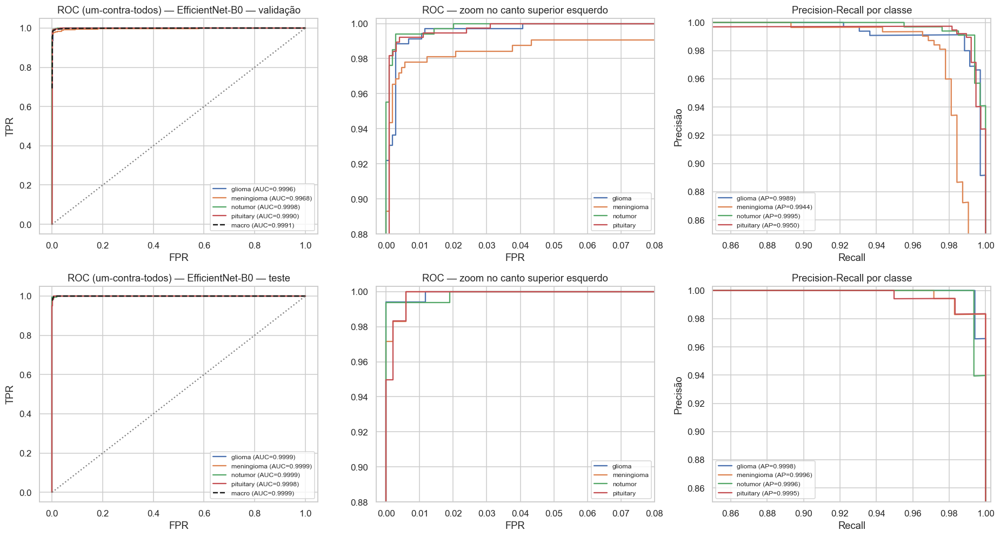

AP                AUC          
Conjunto      teste validação    teste validação
Classe                                          
glioma      0.99980   0.99892  0.99993   0.99963
meningioma  0.99965   0.99443  0.99988   0.99683
notumor     0.99961   0.99950  0.99988   0.99983
pituitary   0.99953   0.99499  0.99983   0.99905

In [20]:
roc_pr(NOME_C)

### 2.3 Log-loss

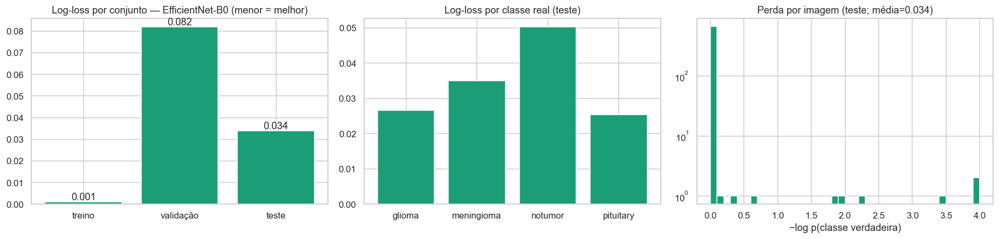

As 34 imagens com maior perda (5% do teste) respondem por 99.9% do log-loss total.


In [21]:
logloss_m(NOME_C)

### 2.4 Acurácia treino × validação × teste (variância)
Para a CNN, o painel da direita mostra a acurácia de treino × validação época a época (o histórico da CNN registra a acurácia de treino).

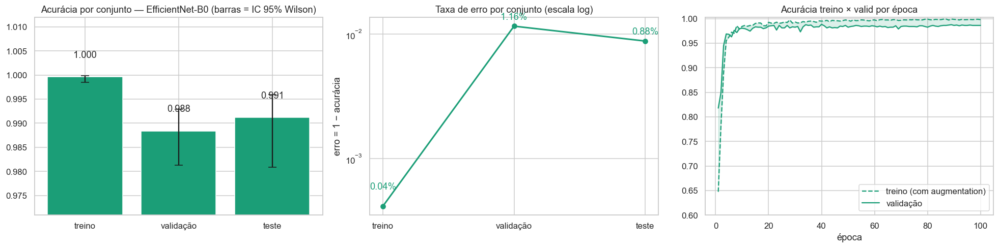

Gaps (p.p.): {'treino−valid': 1.12, 'valid−teste': -0.28, 'treino−teste': 0.84}
valid=0.9884 vs teste=0.9912: p-valor (2 proporções)=0.562 → compatível com ruído amostral
Diagnóstico: acc treino=0.9996 | gap treino−valid=1.12 p.p. → variância baixa; viés baixo.


In [22]:
variancia(NOME_C)

### 2.5 Loss de treino e taxa de aprendizado
O LR da CNN é **reconstruído** por fórmula (cosine, `lr=3e-4`, `T_max` = nº de épocas treinadas), pois o treino não o gravou.

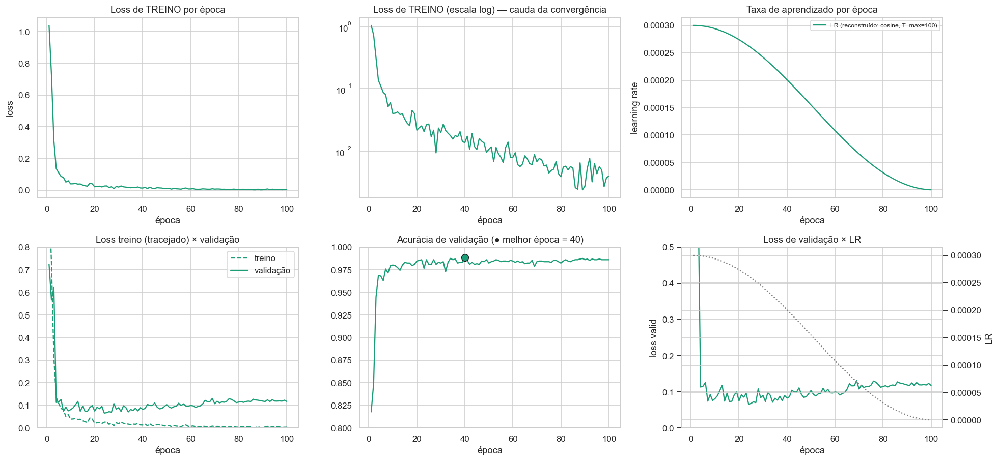

,EfficientNet-B0
Épocas,100
Melhor época,40
Menor loss de treino,0.002369
Loss de treino final,0.003946
Menor loss valid,0.066425
Época da menor loss valid,24
LR inicial,0.0003
LR final,0.0
Tempo total (min),230.536821
Épocas c/ loss de treino subindo >30%,16


In [23]:
treino_m(NOME_C)

### 2.6 Matrizes de confusão e métricas por classe

--- EfficientNet-B0 — validação
               precision    recall  f1-score   support

      glioma     0.9913    0.9884    0.9899       346
  meningioma     0.9811    0.9780    0.9795       318
     notumor     0.9911    0.9940    0.9925       335
   pituitary     0.9895    0.9921    0.9908       380

    accuracy                         0.9884      1379
   macro avg     0.9882    0.9881    0.9882      1379
weighted avg     0.9884    0.9884    0.9884      1379

--- EfficientNet-B0 — teste
               precision    recall  f1-score   support

      glioma     0.9941    0.9941    0.9941       170
  meningioma     0.9886    0.9830    0.9858       176
     notumor     1.0000    0.9936    0.9968       156
   pituitary     0.9834    0.9944    0.9889       179

    accuracy                         0.9912       681
   macro avg     0.9915    0.9913    0.9914       681
weighted avg     0.9912    0.9912    0.9912       681



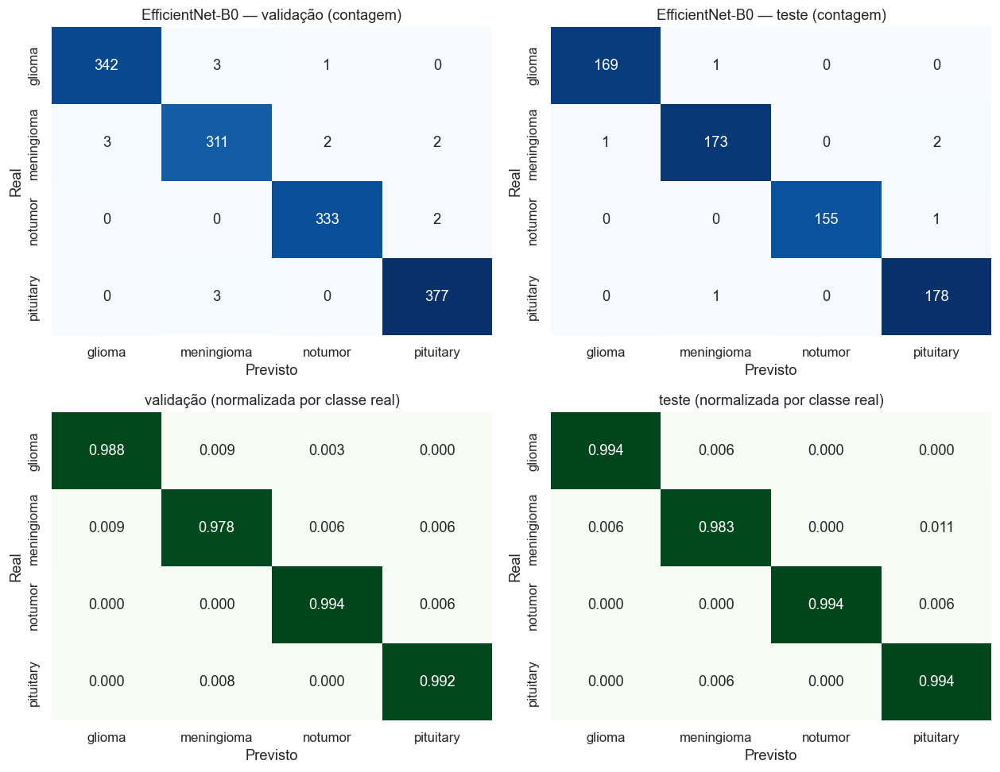

Confusões mais comuns no teste (real → previsto): meningioma→pituitary (2); glioma→meningioma (1); meningioma→glioma (1); notumor→pituitary (1)


In [24]:
confusao_m(NOME_C)

### 2.7 Calibração e predição seletiva

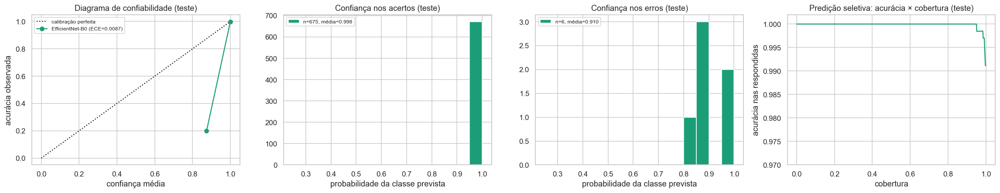

Limiar de confiança,Cobertura,Acurácia nas respondidas,Encaminhadas p/ revisão,Erros que escapam
0.500000,1.000000,0.991200,0,6
0.700000,0.997100,0.991200,2,6
0.800000,0.997100,0.991200,2,6
0.900000,0.989700,0.997000,7,2
0.950000,0.988300,0.997000,8,2
0.990000,0.982400,0.998500,12,1


{'ECE': np.float64(0.008708192388391697), 'Brier': 0.01580043748668804, 'Confiança média (acertos)': np.float32(0.99839896), 'Confiança média (erros)': np.float32(0.9101533)}


In [25]:
calibracao_m(NOME_C)

### 2.8 Visão clínica: tumor × sem tumor

Conjunto,Sensibilidade,Especificidade,VPP,VPN,Falsos negativos,Falsos positivos,AUC binária,"Especificidade c/ sens ≥ 99,5%",Acc. do tipo (só tumores)
validação,0.997100,0.994000,0.998100,0.991100,3,2,0.999800,0.994000,0.986600
teste,1.000000,0.993600,0.998100,1.000000,0,1,0.999900,0.993600,0.990500


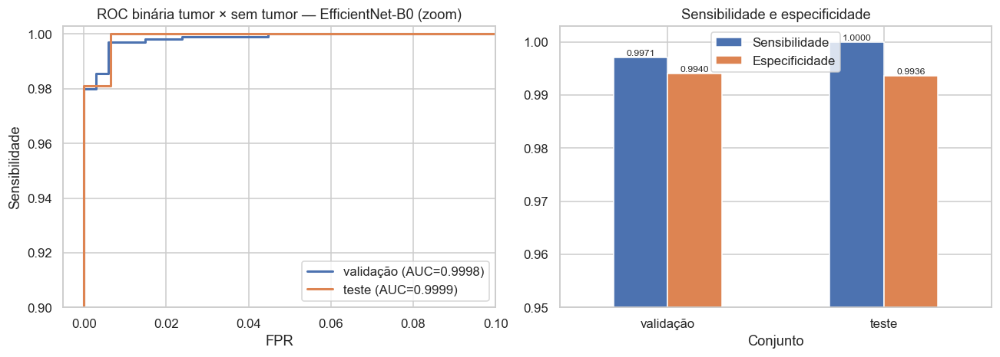

In [26]:
clinica_m(NOME_C)

### 2.9 Intervalos de confiança (bootstrap) e teste limpo

Conjunto,Métrica,Média,IC95% inf,IC95% sup
validação,Acurácia,0.988300,0.982600,0.993500
validação,F1 macro,0.988100,0.982500,0.993400
validação,Log-loss,0.084000,0.043800,0.130000
teste,Acurácia,0.991300,0.982400,0.997100
teste,F1 macro,0.991500,0.983000,0.997200
teste,Log-loss,0.033600,0.008500,0.069100


Conjunto,Subconjunto,n,Acurácia,IC95 inf,IC95 sup,Erros,Log-loss
validação,completo,1379,0.988400,0.981200,0.992800,16,0.081900
validação,limpo (sem quase-duplicata),1180,0.987300,0.979100,0.992300,15,0.087400
validação,só com quase-duplicata,199,0.995000,0.972100,0.999100,1,0.049100
teste,completo,681,0.991200,0.980900,0.996000,6,0.033900
teste,limpo (sem quase-duplicata),570,0.989500,0.977200,0.995200,6,0.040500
teste,só com quase-duplicata,111,1.000000,0.966500,1.000000,0,0.000000


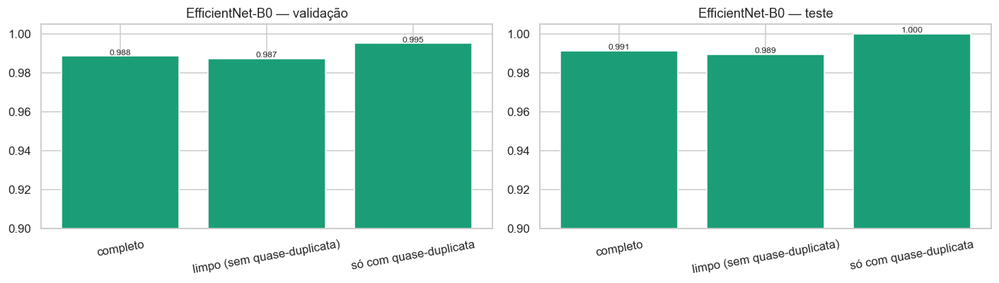

In [27]:
boot_m(NOME_C); limpo_m(NOME_C)

### 2.10 Robustez a perturbações

  original                   acc=0.983 (17s)


  ruído gaussiano σ=10       acc=0.258 (34s)


  ruído gaussiano σ=25       acc=0.200 (49s)


  desfoque (raio 2)          acc=0.575 (61s)


  desfoque (raio 4)          acc=0.442 (74s)


  brilho −30%                acc=0.983 (86s)


... (3 outputs left out)

  rotação 10°                acc=0.983 (133s)


  flip horizontal            acc=0.983 (145s)


  oclusão 25% da largura     acc=0.983 (157s)


,Acurácia,Log-loss
original,0.9833,0.0946
ruído gaussiano σ=10,0.2583,11.3506
ruído gaussiano σ=25,0.2000,11.2604
desfoque (raio 2),0.5750,2.0872
desfoque (raio 4),0.4417,3.1463
brilho −30%,0.9833,0.0662
brilho +30%,0.9833,0.0879
contraste −40%,0.9833,0.0440
JPEG q=20,0.9833,0.0613
rotação 10°,0.9833,0.1550


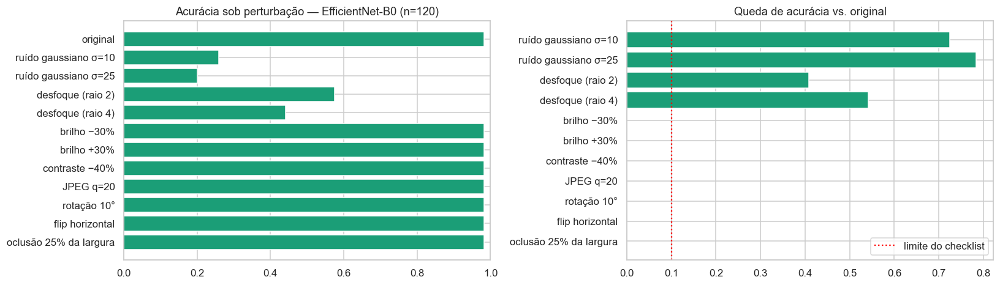

Queda média: 22.3 p.p.


In [28]:
robustez_m(NOME_C)

### 2.11 Grad-CAM e análise de erros

EfficientNet-B0: 6 erros no teste


,Arquivo,Real,Previsto,Confiança,Quase-duplicata no treino?
0,Te-gl_62_jpg.rf.e5510a0f35d1fd15d06d9a14cacfa3...,glioma,meningioma,0.988,False
1,Tr-aug-me_61_jpg.rf.382cf75f039a56fb94cc6df82e...,meningioma,pituitary,0.851,False
2,Tr-me_14_jpg.rf.a95e862ba6e125e89d602ae6f12479...,meningioma,glioma,0.844,False
3,Tr-me_964_jpg.rf.6d728af1f74ceef073eb6acf88f7c...,meningioma,pituitary,0.896,False
4,Tr-no_907_jpg.rf.c9992476b360bb8a91dc09eceaa89...,notumor,pituitary,0.999,False
5,Tr-pi_1255_jpg.rf.4a24eef12abfbc89962f61594be4...,pituitary,meningioma,0.883,False


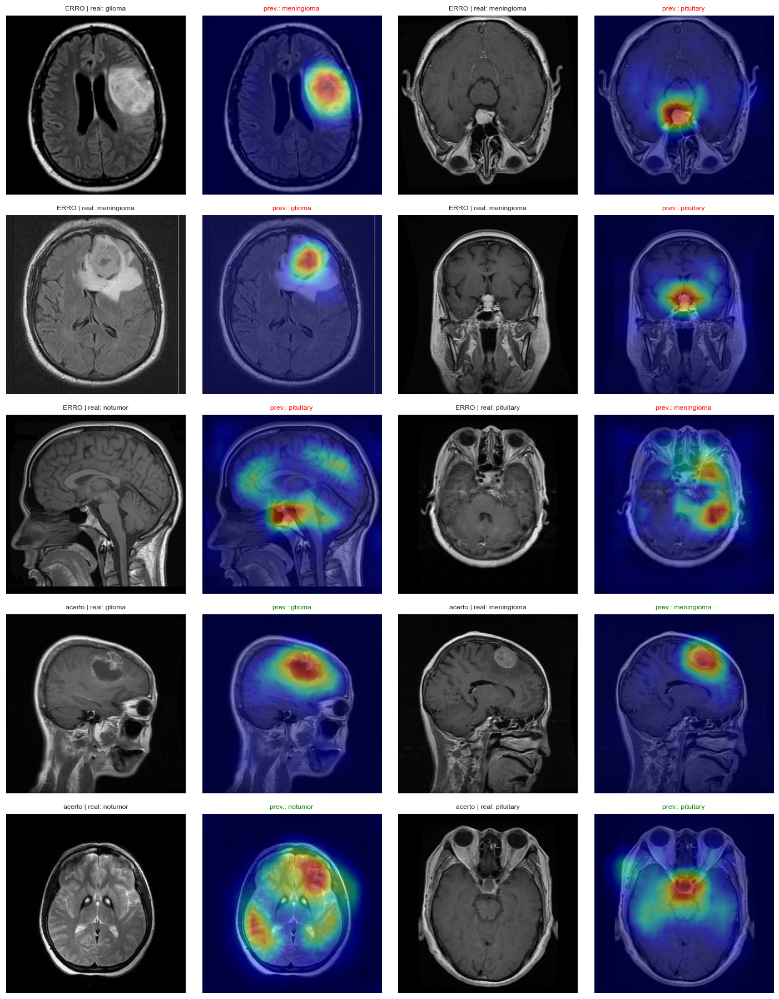

In [29]:
erros_gradcam_m(NOME_C)

### 2.12 Eficiência, determinismo e checklist de aprovação da CNN

In [30]:
eficiencia_m(NOME_C); checklist_m(NOME_C)

,EfficientNet-B0
Parâmetros (M),4.013
GFLOPs/imagem,4.013
Peso em disco (MB),16.354
Latência mediana (ms),144.155
Latência p95 (ms),162.324


Determinismo (dif. máx. entre 2 execuções; 0 = determinístico): 0.0


Critério,Valor,Meta,Status
Acurácia no teste,0.991200,≥ 0.97,✅
Acurácia no teste LIMPO (sem quase-duplicatas),0.989500,≥ 0.97,✅
Menor recall entre as classes (teste),0.983000,≥ 0.95,✅
Sensibilidade p/ tumor (teste),1.000000,≥ 0.99,✅
AUC macro (teste),0.999900,≥ 0.99,✅
Log-loss (teste),0.033900,≤ 0.15,✅
ECE — calibração (teste),0.008700,≤ 0.03,✅
Gap treino − valid (variância),0.011200,≤ 0.03,✅
|Gap valid − teste|,0.002800,≤ 0.02,✅
Queda média de acurácia sob perturbação,0.223500,≤ 0.1,❌


EfficientNet-B0: 10/11 critérios atendidos


In [31]:
parecer_m(NOME_C)


**Parecer — EfficientNet-B0.** Acurácia no teste **99.12%** (6 erros em 681); no teste limpo **98.95%**. AUC macro 0.9999, log-loss 0.0339, ECE 0.0087.
Variância: gap treino−valid 1.12 p.p., valid−teste -0.28 p.p. Sensibilidade p/ tumor 100.00% (0 falsos negativos).
Robustez: queda média de 22.3 p.p. sob perturbações. Checklist: 10/11 critérios; não atendidos: Queda média de acurácia sob perturbação.


---
# ETAPA 3 — Comparação entre os 2 modelos
Aqui os dois modelos são colocados **lado a lado**, nas mesmas imagens, com os mesmos critérios. Tudo reaproveita os resultados das Etapas 1 e 2.

### 3.1 Métricas lado a lado

treino                   validação                  \
                    YOLO11s-cls EfficientNet-B0 YOLO11s-cls EfficientNet-B0   
Acurácia (top-1)         0.9994          0.9996      0.9710          0.9884   
Acurácia balanceada      0.9994          0.9996      0.9703          0.9881   
Precisão macro           0.9994          0.9996      0.9707          0.9882   
Recall macro             0.9994          0.9996      0.9703          0.9881   
F1 macro                 0.9994          0.9996      0.9703          0.9882   
MCC                      0.9992          0.9994      0.9614          0.9845   
Kappa                    0.9992          0.9994      0.9613          0.9845   
AUC macro (OvR)          1.0000          1.0000      0.9966          0.9988   
AP macro (PR)            1.0000          1.0000      0.9923          0.9970   
Log-loss                 0.0094          0.0010      0.1218          0.0819   
Brier                    0.0027          0.0006      0.0487          0.0237   
ECE                      0.0074          0.0004      0.0137          0.0116   
Erros (nº)               3.0000          2.0000     40.0000         16.0000   
Imagens               4819.0000       4819.0000   1379.0000       1379.0000   

                          teste                  
                    YOLO11s-cls EfficientNet-B0  
Acurácia (top-1)         0.9794          0.9912  
Acurácia balanceada      0.9796          0.9913  
Precisão macro           0.9792          0.9915  
Recall macro             0.9796          0.9913  
F1 macro                 0.9794          0.9914  
MCC                      0.9726          0.9882  
Kappa                    0.9726          0.9882  
AUC macro (OvR)          0.9984          0.9999  
AP macro (PR)            0.9959          0.9996  
Log-loss                 0.0780          0.0339  
Brier                    0.0324          0.0158  
ECE                      0.0050          0.0087  
Erros (nº)              14.0000          6.0000  
Imagens                681.0000        681.0000

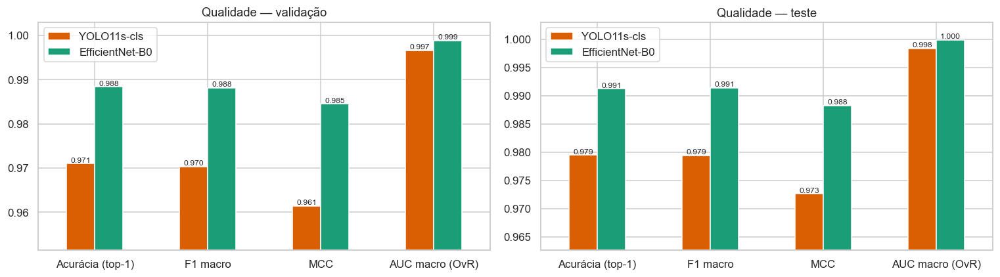

In [32]:
MET = pd.DataFrame({(NOME_S[s], m): R["met"][m][NOME_S[s]] for s in SPLITS for m in MODELOS}); display(MET.round(4)); salvar_tab(MET, "3_comp_01_metricas.csv")
chave = ["Acurácia (top-1)", "F1 macro", "MCC", "AUC macro (OvR)"]
fig, ax = plt.subplots(1, len(SV), figsize=(7 * len(SV), 4)); ax = np.atleast_1d(ax)
for a, s in zip(ax, SV):
    d = pd.DataFrame({m: MET[(NOME_S[s], m)].loc[chave] for m in MODELOS}); d.plot.bar(ax=a, rot=0, color=[COR[m] for m in MODELOS]); a.set_ylim(max(0.9, d.min().min() - 0.01), 1.003); a.set_title(f"Qualidade — {NOME_S[s]}")
    for c in a.containers: a.bar_label(c, fmt="%.3f", fontsize=8)
plt.tight_layout(); salvar_fig("3_comp_01_metricas.png")

### 3.2 Curvas ROC e Precision-Recall (sobrepostas)

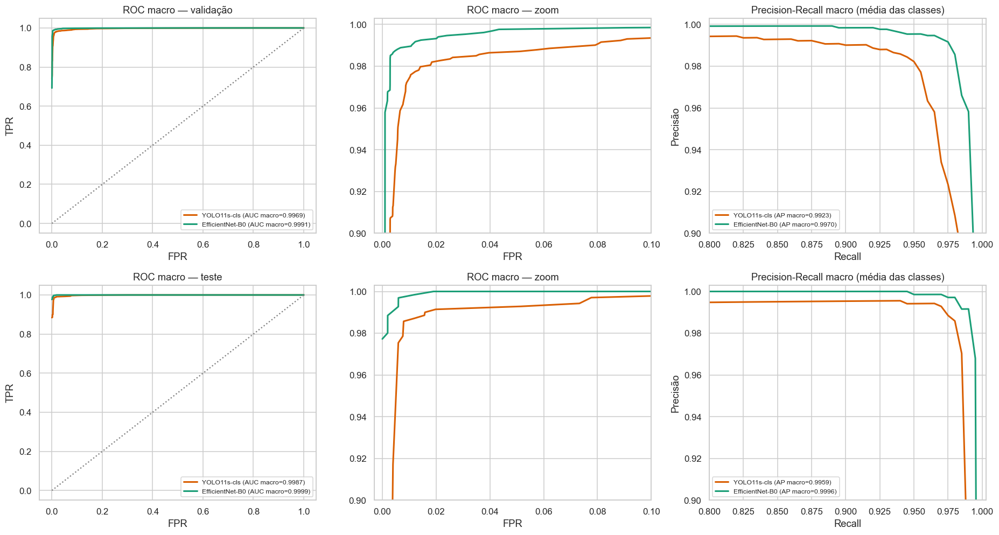

AP                         AUC            
Modelo               EfficientNet-B0 YOLO11s-cls EfficientNet-B0 YOLO11s-cls
Conjunto  Classe                                                            
teste     glioma             0.99980     0.99539         0.99993     0.99744
          meningioma         0.99965     0.99077         0.99988     0.99709
          notumor            0.99961     0.99955         0.99988     0.99987
          pituitary          0.99953     0.99787         0.99983     0.99909
validação glioma             0.99892     0.99313         0.99963     0.99717
          meningioma         0.99443     0.97866         0.99683     0.99006
          notumor            0.99950     0.99883         0.99983     0.99963
          pituitary          0.99499     0.99863         0.99905     0.99944

In [33]:
fig, ax = plt.subplots(len(SV), 3, figsize=(17, 4.6 * len(SV))); ax = np.atleast_2d(ax)
for r, s in enumerate(SV):
    for m in MODELOS:
        fm, tm, am = roc_macro(Y[s], PROB[m][s]); ax[r, 0].plot(fm, tm, color=COR[m], lw=2, label=f"{m} (AUC macro={am:.4f})"); ax[r, 1].plot(fm, tm, color=COR[m], lw=2)
        Yb = np.eye(NC)[Y[s]]; grade = np.linspace(0, 1, 201); pm = np.mean([np.interp(grade, precision_recall_curve(Yb[:, i], PROB[m][s][:, i])[1][::-1], precision_recall_curve(Yb[:, i], PROB[m][s][:, i])[0][::-1]) for i in range(NC)], axis=0)
        ax[r, 2].plot(grade, pm, color=COR[m], lw=2, label=f"{m} (AP macro={average_precision_score(Yb, PROB[m][s], average='macro'):.4f})")
    ax[r, 0].plot([0, 1], [0, 1], ":", color="gray"); ax[r, 0].set_title(f"ROC macro — {NOME_S[s]}"); ax[r, 0].set_xlabel("FPR"); ax[r, 0].set_ylabel("TPR"); ax[r, 0].legend(loc="lower right", fontsize=8)
    ax[r, 1].set_xlim(-0.003, 0.1); ax[r, 1].set_ylim(0.9, 1.003); ax[r, 1].set_title("ROC macro — zoom"); ax[r, 1].set_xlabel("FPR")
    ax[r, 2].set_xlim(0.8, 1.003); ax[r, 2].set_ylim(0.9, 1.003); ax[r, 2].set_title("Precision-Recall macro (média das classes)"); ax[r, 2].set_xlabel("Recall"); ax[r, 2].set_ylabel("Precisão"); ax[r, 2].legend(loc="lower left", fontsize=8)
plt.tight_layout(); salvar_fig("3_comp_02_roc_pr.png")
auc_cls = pd.DataFrame([{"Conjunto": NOME_S[s], "Modelo": m, "Classe": c, "AUC": roc_auc_score(Y[s] == i, PROB[m][s][:, i]), "AP": average_precision_score(Y[s] == i, PROB[m][s][:, i])} for s in SV for m in MODELOS for i, c in enumerate(CLASSES)])
display(auc_cls.pivot_table(index=["Conjunto", "Classe"], columns="Modelo", values=["AUC", "AP"]).round(5)); salvar_tab(auc_cls, "3_comp_02_auc_por_classe.csv", index=False)

### 3.3 Log-loss comparado

,treino,validação,teste
YOLO11s-cls,0.0094,0.1218,0.0780
EfficientNet-B0,0.0010,0.0819,0.0339


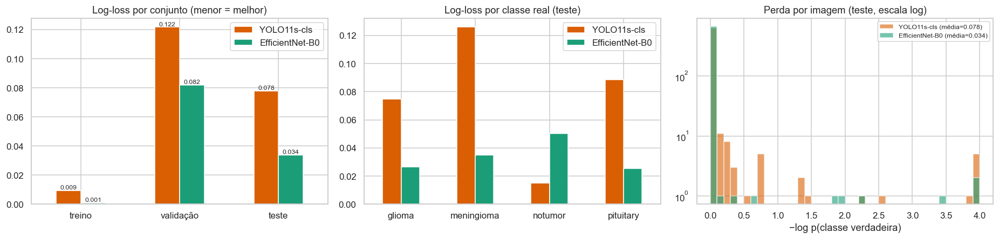

In [34]:
LL = pd.DataFrame({NOME_S[s]: {m: log_loss(Y[s], PROB[m][s], labels=list(range(NC))) for m in MODELOS} for s in SPLITS}); display(LL.round(4)); salvar_tab(LL, "3_comp_03_logloss.csv")
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
LL.T.plot.bar(ax=ax[0], rot=0, color=[COR[m] for m in LL.index]); ax[0].set_title("Log-loss por conjunto (menor = melhor)")
for c in ax[0].containers: ax[0].bar_label(c, fmt="%.3f", fontsize=8)
llc = pd.DataFrame({m: [perda_amostra(Y["test"], PROB[m]["test"])[Y["test"] == i].mean() for i in range(NC)] for m in MODELOS}, index=CLASSES); llc.plot.bar(ax=ax[1], rot=0, color=[COR[m] for m in MODELOS]); ax[1].set_title("Log-loss por classe real (teste)")
for m in MODELOS:
    l = perda_amostra(Y["test"], PROB[m]["test"]); ax[2].hist(np.clip(l, 0, 4), bins=np.linspace(0, 4, 41), alpha=.6, color=COR[m], label=f"{m} (média={l.mean():.3f})")
ax[2].set_yscale("log"); ax[2].set_title("Perda por imagem (teste, escala log)"); ax[2].set_xlabel("−log p(classe verdadeira)"); ax[2].legend(fontsize=8)
plt.tight_layout(); salvar_fig("3_comp_03_logloss.png")

### 3.4 Acurácia treino × validação × teste — qual modelo tem mais variância?
Barras com **IC de Wilson 95%** para os dois modelos. Quanto maior a queda de treino → valid → teste, maior a variância (overfitting); intervalos que se sobrepõem indicam diferenças que podem ser ruído amostral.

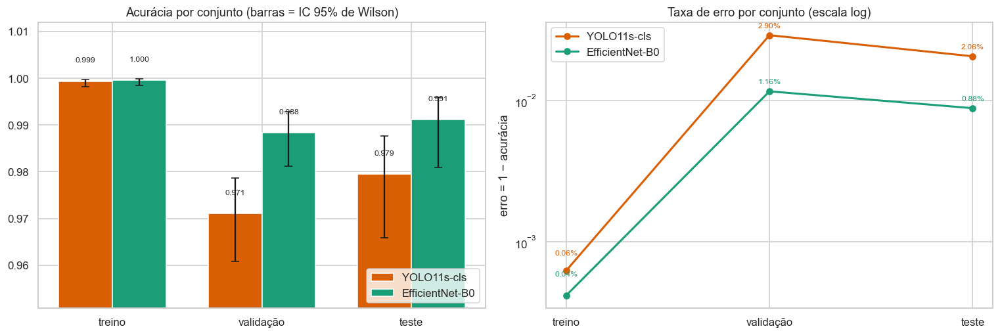

,gap treino−valid (p.p.),gap valid−teste (p.p.),gap treino−teste (p.p.)
YOLO11s-cls,2.84,-0.84,1.99
EfficientNet-B0,1.12,-0.28,0.84


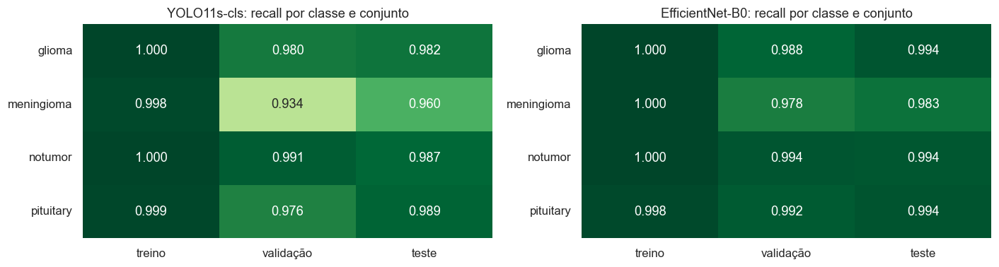

In [35]:
VAR = pd.DataFrame([dict(Modelo=m, Conjunto=NOME_S[s], Acurácia=(PRED[m][s] == Y[s]).mean(), lo=wilson(int((PRED[m][s] == Y[s]).sum()), len(Y[s]))[0], hi=wilson(int((PRED[m][s] == Y[s]).sum()), len(Y[s]))[1]) for m in MODELOS for s in SPLITS])
salvar_tab(VAR, "3_comp_04_acuracia_por_conjunto.csv", index=False); fig, ax = plt.subplots(1, 2, figsize=(14, 4.8)); w = 0.36; x = np.arange(len(SPLITS))
for j, m in enumerate(MODELOS):
    d = VAR[VAR["Modelo"] == m]; ax[0].bar(x + (j - .5) * w, d["Acurácia"], w, color=COR[m], label=m, yerr=[d["Acurácia"] - d["lo"], d["hi"] - d["Acurácia"]], capsize=4)
    for xi, v in zip(x + (j - .5) * w, d["Acurácia"]): ax[0].text(xi, v + 0.004, f"{v:.3f}", ha="center", fontsize=8)
    ax[1].plot([NOME_S[s] for s in SPLITS], 1 - d["Acurácia"], "o-", color=COR[m], lw=2, label=m)
    for xi, v in enumerate(1 - d["Acurácia"]): ax[1].text(xi, v * 1.12 + 1e-4, f"{100*v:.2f}%", ha="center", fontsize=8, color=COR[m])
ax[0].set_xticks(x); ax[0].set_xticklabels([NOME_S[s] for s in SPLITS]); ax[0].set_ylim(max(0.9, VAR["lo"].min() - 0.01), 1.012); ax[0].set_title("Acurácia por conjunto (barras = IC 95% de Wilson)"); ax[0].legend(loc="lower right")
ax[1].set_yscale("log"); ax[1].set_title("Taxa de erro por conjunto (escala log)"); ax[1].set_ylabel("erro = 1 − acurácia"); ax[1].legend()
plt.tight_layout(); salvar_fig("3_comp_04_acuracia_treino_val_teste.png")
GAP = pd.DataFrame(R["gap"]).T; GAP.columns = [f"gap {c}" for c in GAP.columns]; display((GAP * 100).round(2).rename(columns=lambda c: c + " (p.p.)")); salvar_tab(GAP, "3_comp_04_gaps.csv")
rc = pd.DataFrame({(m, NOME_S[s]): recall_score(Y[s], PRED[m][s], average=None) for m in MODELOS for s in SPLITS}, index=CLASSES)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for a, m in zip(ax, MODELOS): sns.heatmap(rc[m], annot=True, fmt=".3f", cmap="YlGn", vmin=0.9, vmax=1, ax=a, cbar=False); a.set_title(f"{m}: recall por classe e conjunto")
plt.tight_layout(); salvar_fig("3_comp_04_recall_classe_conjunto.png")

### 3.5 Treinamento: loss, taxa de aprendizado e velocidade de convergência

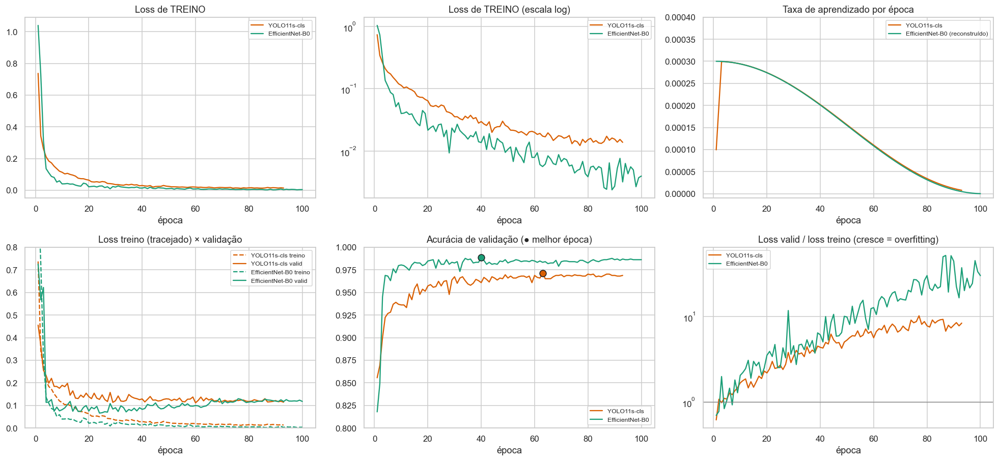

,YOLO11s-cls,EfficientNet-B0
Épocas,93,100
Melhor época,63,40
Menor loss de treino,0.0122,0.002369
Loss de treino final,0.01374,0.003946
Menor loss valid,0.11184,0.066425
Época da menor loss valid,60,24
LR inicial,0.000099,0.0003
LR final,0.000008,0.0
Tempo total (min),801.233333,230.536821
Épocas c/ loss de treino subindo >30%,0,16


Obs.: as losses do YOLO e da CNN não têm a mesma escala (implementações/regularização diferentes): compare o FORMATO das curvas. Tempos de treino dependem do hardware (o YOLO treinou em CPU).


In [36]:
fig, ax = plt.subplots(2, 3, figsize=(18, 8.4))
for m, ep, tl, vl, va, lr in ((NOME_Y, hist_y["epoch"], hist_y["train/loss"], hist_y["val/loss"], hist_y["metrics/accuracy_top1"], hist_y["lr/pg0"]), (NOME_C, hist_c["epoca"], hist_c["loss_treino"], hist_c["loss_val"], hist_c["acc_val"], hist_c["lr_reconstruido"])):
    c = COR[m]; ax[0, 0].plot(ep, tl, color=c, label=m); ax[0, 1].plot(ep, tl, color=c, label=m); ax[0, 2].plot(ep, lr, color=c, label=m + (" (reconstruído)" if m == NOME_C else ""))
    ax[1, 0].plot(ep, tl, "--", color=c, label=f"{m} treino"); ax[1, 0].plot(ep, vl, color=c, label=f"{m} valid"); ax[1, 1].plot(ep, va, color=c, label=m)
    b = int(ep.iloc[va.reset_index(drop=True).idxmax()]); ax[1, 1].scatter([b], [va.max()], s=70, color=c, edgecolor="k", zorder=5)
    ax[1, 2].plot(ep, vl / tl, color=c, label=m)
ax[0, 0].set_title("Loss de TREINO"); ax[0, 1].set_yscale("log"); ax[0, 1].set_title("Loss de TREINO (escala log)"); ax[0, 2].set_title("Taxa de aprendizado por época"); ax[0, 2].set_ylim(-1e-5, 4e-4)
ax[1, 0].set_ylim(0, 0.8); ax[1, 0].set_title("Loss treino (tracejado) × validação"); ax[1, 1].set_ylim(0.8, 1.0); ax[1, 1].set_title("Acurácia de validação (● melhor época)")
ax[1, 2].set_yscale("log"); ax[1, 2].axhline(1, color="gray", lw=.8); ax[1, 2].set_title("Loss valid / loss treino (cresce = overfitting)")
for a in ax.ravel(): a.set_xlabel("época"); a.legend(fontsize=8)
plt.tight_layout(); salvar_fig("3_comp_05_treino.png")
TR = pd.DataFrame(R["treino"]); display(TR); salvar_tab(TR, "3_comp_05_resumo_treino.csv")
print("Obs.: as losses do YOLO e da CNN não têm a mesma escala (implementações/regularização diferentes): compare o FORMATO das curvas. Tempos de treino dependem do hardware (o YOLO treinou em CPU).")

### 3.6 Matrizes de confusão e desempenho por classe (teste)

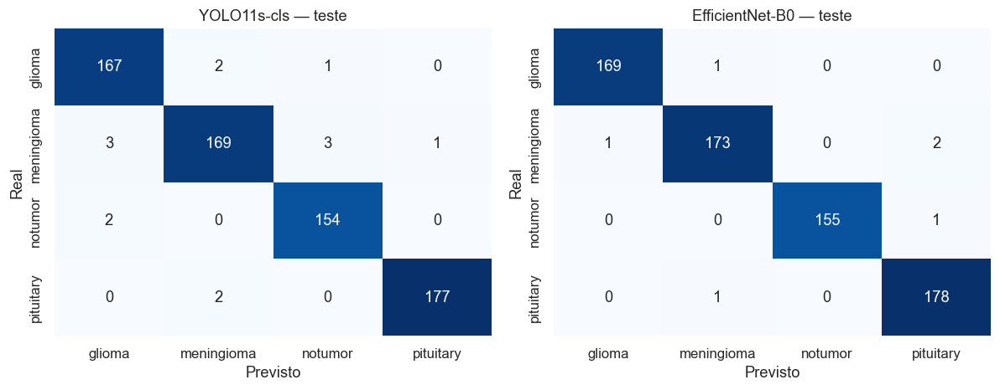

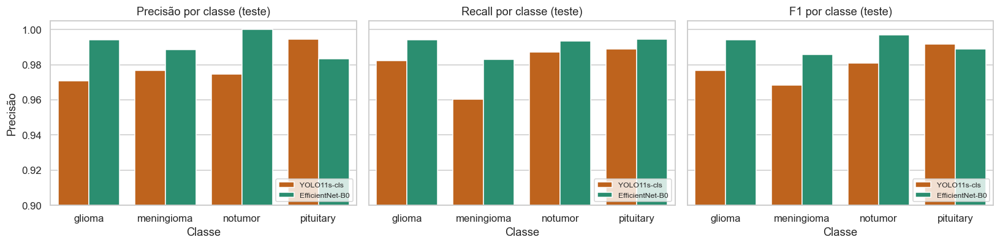

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
for a, m in zip(ax, MODELOS):
    cm = confusion_matrix(Y["test"], PRED[m]["test"]); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=a, cbar=False); a.set_title(f"{m} — teste"); a.set_xlabel("Previsto"); a.set_ylabel("Real")
plt.tight_layout(); salvar_fig("3_comp_06_confusao.png")
PC = pd.concat([R["pc"][m].assign(Modelo=m) for m in MODELOS]); salvar_tab(PC, "3_comp_06_por_classe.csv", index=False)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for a, met in zip(ax, ("Precisão", "Recall", "F1")):
    sns.barplot(data=PC[PC["Conjunto"] == "teste"], x="Classe", y=met, hue="Modelo", palette=COR, ax=a); a.set_ylim(0.9, 1.005); a.set_title(f"{met} por classe (teste)"); a.legend(fontsize=8, loc="lower right")
plt.tight_layout(); salvar_fig("3_comp_06_por_classe.png")

### 3.7 Calibração e predição seletiva (comparadas)

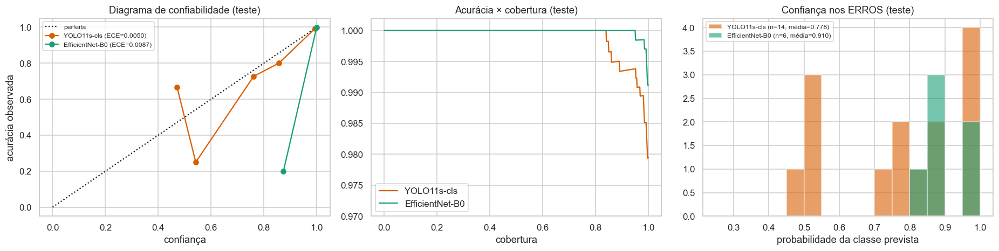

,YOLO11s-cls,EfficientNet-B0
ECE,0.0050,0.0087
Brier,0.0324,0.0158
Confiança média (acertos),0.9870,0.9984
Confiança média (erros),0.7777,0.9102


YOLO11s-cls                                             \
                      Cobertura Acurácia nas respondidas Erros que escapam   
Limiar de confiança                                                          
0.50                     0.9956                   0.9808                13   
0.70                     0.9897                   0.9852                10   
0.80                     0.9736                   0.9894                 7   
0.90                     0.9515                   0.9938                 4   
0.95                     0.9236                   0.9936                 4   
0.99                     0.8385                   1.0000                 0   

                    EfficientNet-B0                                             
                          Cobertura Acurácia nas respondidas Erros que escapam  
Limiar de confiança                                                             
0.50                         1.0000                   0.9912                 6  
0.70                         0.9971                   0.9912                 6  
0.80                         0.9971                   0.9912                 6  
0.90                         0.9897                   0.9970                 2  
0.95                         0.9883                   0.9970                 2  
0.99                         0.9824                   0.9985                 1

In [38]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4)); bins = np.linspace(0, 1, 11); ax[0].plot([0, 1], [0, 1], "k:", label="perfeita")
for m in MODELOS:
    conf, ok = PROB[m]["test"].max(1), PRED[m]["test"] == Y["test"]; xs, ys = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mk = (conf > lo) & (conf <= hi)
        if mk.sum() >= 3: xs.append(conf[mk].mean()); ys.append(ok[mk].mean())
    ax[0].plot(xs, ys, "o-", color=COR[m], label=f"{m} (ECE={R['cal'][m]['ECE']:.4f})")
    o = np.argsort(-conf); ax[1].plot(np.arange(1, len(o) + 1) / len(o), np.cumsum(ok[o]) / np.arange(1, len(o) + 1), color=COR[m], label=m)
    v = conf[~ok]
    if len(v): ax[2].hist(v, bins=np.linspace(0.25, 1, 16), alpha=.6, color=COR[m], label=f"{m} (n={len(v)}, média={v.mean():.3f})")
ax[0].set_title("Diagrama de confiabilidade (teste)"); ax[0].set_xlabel("confiança"); ax[0].set_ylabel("acurácia observada"); ax[0].legend(fontsize=8)
ax[1].set_ylim(0.97, 1.002); ax[1].set_title("Acurácia × cobertura (teste)"); ax[1].set_xlabel("cobertura"); ax[1].legend(); ax[2].set_title("Confiança nos ERROS (teste)"); ax[2].set_xlabel("probabilidade da classe prevista"); ax[2].legend(fontsize=8)
plt.tight_layout(); salvar_fig("3_comp_07_calibracao.png")
CAL = pd.DataFrame(R["cal"]); display(CAL.round(4)); salvar_tab(CAL, "3_comp_07_calibracao.csv")
display(pd.concat({m: R["sel"][m].set_index("Limiar de confiança")[["Cobertura", "Acurácia nas respondidas", "Erros que escapam"]] for m in MODELOS}, axis=1).round(4))

### 3.8 Visão clínica comparada (tumor × sem tumor)

Conjunto,Sensibilidade,Especificidade,VPP,VPN,Falsos negativos,Falsos positivos,AUC binária,"Especificidade c/ sens ≥ 99,5%",Acc. do tipo (só tumores),Modelo
validação,0.992300,0.991000,0.997100,0.976500,8,3,0.999600,0.964200,0.964600,YOLO11s-cls
teste,0.992400,0.987200,0.996200,0.974700,4,2,0.999900,0.987200,0.977100,YOLO11s-cls
validação,0.997100,0.994000,0.998100,0.991100,3,2,0.999800,0.994000,0.986600,EfficientNet-B0
teste,1.000000,0.993600,0.998100,1.000000,0,1,0.999900,0.993600,0.990500,EfficientNet-B0


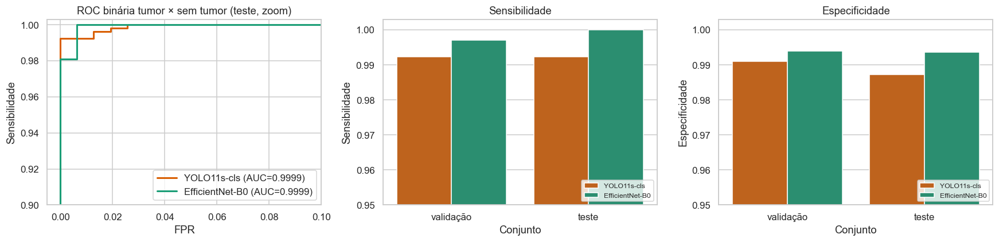

In [39]:
CLIN = pd.concat([R["clin"][m].assign(Modelo=m) for m in MODELOS]); display(CLIN.round(4).style.hide(axis="index")); salvar_tab(CLIN, "3_comp_08_visao_clinica.csv", index=False)
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for m in MODELOS:
    yt = Y["test"] != i_nt; fpr, tpr, _ = roc_curve(yt, 1 - PROB[m]["test"][:, i_nt]); ax[0].plot(fpr, tpr, color=COR[m], lw=2, label=f"{m} (AUC={roc_auc_score(yt, 1 - PROB[m]['test'][:, i_nt]):.4f})")
ax[0].set_xlim(-0.005, 0.1); ax[0].set_ylim(0.9, 1.003); ax[0].set_title("ROC binária tumor × sem tumor (teste, zoom)"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("Sensibilidade"); ax[0].legend(loc="lower right")
for a, met in zip(ax[1:], ("Sensibilidade", "Especificidade")):
    sns.barplot(data=CLIN, x="Conjunto", y=met, hue="Modelo", palette=COR, ax=a); a.set_ylim(0.95, 1.003); a.set_title(met); a.legend(fontsize=8, loc="lower right")
plt.tight_layout(); salvar_fig("3_comp_08_visao_clinica.png")

### 3.9 Efeito do vazamento: teste completo × limpo

Conjunto,Subconjunto,n,Acurácia,IC95 inf,IC95 sup,Erros,Log-loss,Modelo
validação,completo,1379,0.971000,0.960700,0.978600,40,0.121800,YOLO11s-cls
validação,limpo (sem quase-duplicata),1180,0.967800,0.956100,0.976400,38,0.133800,YOLO11s-cls
validação,só com quase-duplicata,199,0.989900,0.964100,0.997200,2,0.050600,YOLO11s-cls
teste,completo,681,0.979400,0.965800,0.987700,14,0.078000,YOLO11s-cls
teste,limpo (sem quase-duplicata),570,0.977200,0.961400,0.986600,13,0.090700,YOLO11s-cls
teste,só com quase-duplicata,111,0.991000,0.950700,0.998400,1,0.012700,YOLO11s-cls
validação,completo,1379,0.988400,0.981200,0.992800,16,0.081900,EfficientNet-B0
validação,limpo (sem quase-duplicata),1180,0.987300,0.979100,0.992300,15,0.087400,EfficientNet-B0
validação,só com quase-duplicata,199,0.995000,0.972100,0.999100,1,0.049100,EfficientNet-B0
teste,completo,681,0.991200,0.980900,0.996000,6,0.033900,EfficientNet-B0


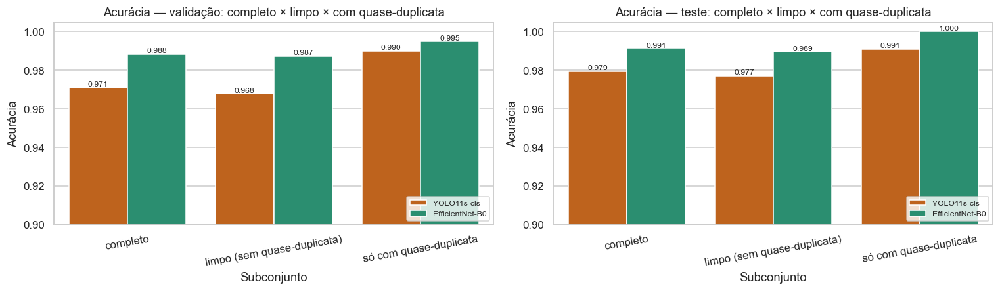

In [40]:
LP = pd.concat([R["limpo"][m].assign(Modelo=m) for m in MODELOS]); display(LP.round(4).style.hide(axis="index")); salvar_tab(LP, "3_comp_09_teste_limpo.csv", index=False)
fig, ax = plt.subplots(1, len(SV), figsize=(7 * len(SV), 4.2)); ax = np.atleast_1d(ax)
for a, s in zip(ax, SV):
    sns.barplot(data=LP[LP["Conjunto"] == NOME_S[s]], x="Subconjunto", y="Acurácia", hue="Modelo", palette=COR, ax=a); a.set_ylim(0.9, 1.005); a.set_title(f"Acurácia — {NOME_S[s]}: completo × limpo × com quase-duplicata"); a.legend(fontsize=8, loc="lower right"); a.tick_params(axis="x", labelrotation=10)
    for c in a.containers: a.bar_label(c, fmt="%.3f", fontsize=8)
plt.tight_layout(); salvar_fig("3_comp_09_teste_limpo.png")

### 3.10 A diferença entre os modelos é real? (estatística pareada)
**Bootstrap pareado** (as duas métricas e a *diferença* usam as mesmas reamostragens — a mesma semente foi usada nas Etapas 1 e 2), **McNemar exato** (compara os erros nas mesmas imagens), **concordância** entre os modelos e **ensemble** (média das probabilidades).

Conjunto,Métrica,YOLO11s-cls [IC95%],EfficientNet-B0 [IC95%],CNN − YOLO [IC95%],IC exclui 0?
validação,Acurácia,0.9708 [0.9616; 0.9797],0.9883 [0.9826; 0.9935],+0.0175 [+0.0102; +0.0247],SIM
validação,F1 macro,0.9701 [0.9610; 0.9791],0.9881 [0.9825; 0.9934],+0.0180 [+0.0104; +0.0260],SIM
validação,Log-loss,0.1228 [0.0825; 0.1680],0.0840 [0.0438; 0.1300],-0.0388 [-0.0809; +0.0016],não
teste,Acurácia,0.9798 [0.9692; 0.9897],0.9913 [0.9824; 0.9971],+0.0115 [+0.0015; +0.0220],SIM
teste,F1 macro,0.9797 [0.9693; 0.9898],0.9915 [0.9830; 0.9972],+0.0118 [+0.0015; +0.0226],SIM
teste,Log-loss,0.0770 [0.0401; 0.1193],0.0336 [0.0085; 0.0691],-0.0434 [-0.0824; -0.0037],SIM


Conjunto,Ambos acertam,Só CNN acerta,Só YOLO acerta,Ambos erram,p McNemar (exato),"Significativo (p<0,05)",Kappa entre modelos,Acc ensemble,Log-loss ensemble
validação,1337,26,2,14,0.000000,SIM,0.970000,0.984000,0.069800
teste,664,11,3,3,0.057400,não,0.970600,0.992700,0.036800


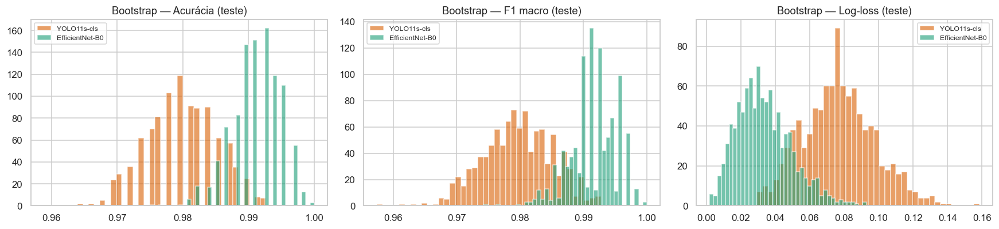

In [41]:
linhas = []
for s in SV:
    for nm, k in (("Acurácia", "acc"), ("F1 macro", "f1"), ("Log-loss", "ll")):
        a, b = R["boot"][NOME_Y][s][k], R["boot"][NOME_C][s][k]; d = b - a
        linhas.append({"Conjunto": NOME_S[s], "Métrica": nm, f"{NOME_Y} [IC95%]": f"{a.mean():.4f} [{ic(a)[0]:.4f}; {ic(a)[1]:.4f}]", f"{NOME_C} [IC95%]": f"{b.mean():.4f} [{ic(b)[0]:.4f}; {ic(b)[1]:.4f}]",
                       "CNN − YOLO [IC95%]": f"{d.mean():+.4f} [{ic(d)[0]:+.4f}; {ic(d)[1]:+.4f}]", "IC exclui 0?": "SIM" if (ic(d)[0] > 0 or ic(d)[1] < 0) else "não"})
BT = pd.DataFrame(linhas); display(BT.style.hide(axis="index")); salvar_tab(BT, "3_comp_10_bootstrap_pareado.csv", index=False)
mc_rows = []
for s in SV:
    oy, oc = PRED[NOME_Y][s] == Y[s], PRED[NOME_C][s] == Y[s]; both, so_c, so_y, nen = (oy & oc).sum(), (~oy & oc).sum(), (oy & ~oc).sum(), (~oy & ~oc).sum(); nd = so_c + so_y
    p = binomtest(int(min(so_c, so_y)), int(nd), 0.5).pvalue if nd else 1.0; pe = (PROB[NOME_Y][s] + PROB[NOME_C][s]) / 2
    mc_rows.append({"Conjunto": NOME_S[s], "Ambos acertam": both, "Só CNN acerta": so_c, "Só YOLO acerta": so_y, "Ambos erram": nen, "p McNemar (exato)": p, "Significativo (p<0,05)": "SIM" if p < .05 else "não",
                    "Kappa entre modelos": cohen_kappa_score(PRED[NOME_Y][s], PRED[NOME_C][s]), "Acc ensemble": accuracy_score(Y[s], pe.argmax(1)), "Log-loss ensemble": log_loss(Y[s], pe, labels=list(range(NC)))})
MC = pd.DataFrame(mc_rows); display(MC.round(4).style.hide(axis="index")); salvar_tab(MC, "3_comp_10_mcnemar_ensemble.csv", index=False)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, (k, tit) in zip(ax, (("acc", "Acurácia"), ("f1", "F1 macro"), ("ll", "Log-loss"))):
    for m in MODELOS: a.hist(R["boot"][m]["test"][k], bins=40, alpha=.6, color=COR[m], label=m)
    a.set_title(f"Bootstrap — {tit} (teste)"); a.legend(fontsize=8)
plt.tight_layout(); salvar_fig("3_comp_10_bootstrap.png")

### 3.11 Robustez comparada

,YOLO11s-cls,EfficientNet-B0
original,0.9750,0.9833
ruído gaussiano σ=10,0.7667,0.2583
ruído gaussiano σ=25,0.4000,0.2000
desfoque (raio 2),0.6667,0.5750
desfoque (raio 4),0.2500,0.4417
brilho −30%,0.9833,0.9833
brilho +30%,0.9667,0.9833
contraste −40%,0.9833,0.9833
JPEG q=20,0.5833,0.9833
rotação 10°,0.9167,0.9833


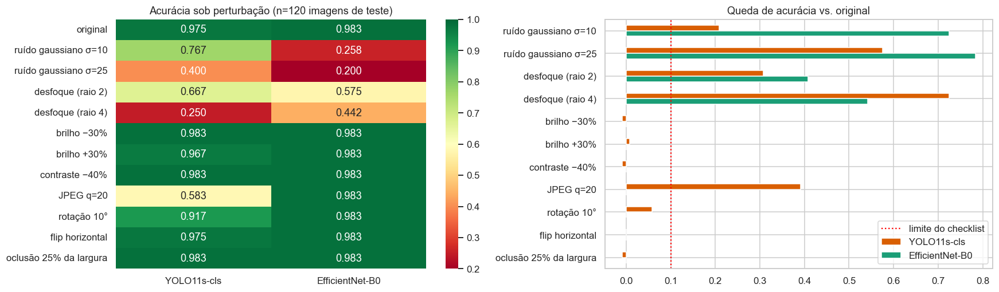

Queda média (p.p.): {'YOLO11s-cls': 20.5, 'EfficientNet-B0': 22.3}


In [42]:
RB = pd.DataFrame({m: {n: v[0] for n, v in R["rob"][m].items()} for m in MODELOS}); display(RB.round(4)); salvar_tab(RB, "3_comp_11_robustez.csv")
drop = pd.DataFrame({m: {n: RB[m]["original"] - RB[m][n] for n in RB.index if n != "original"} for m in MODELOS})
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8)); sns.heatmap(RB, annot=True, fmt=".3f", cmap="RdYlGn", vmin=0.2, vmax=1, ax=ax[0]); ax[0].set_title(f"Acurácia sob perturbação (n={len(y_rob)} imagens de teste)")
drop.plot.barh(ax=ax[1], color=[COR[m] for m in drop.columns]); ax[1].axvline(CRIT["queda_robustez_max"], color="red", ls=":", label="limite do checklist"); ax[1].legend(); ax[1].set_title("Queda de acurácia vs. original"); ax[1].invert_yaxis()
plt.tight_layout(); salvar_fig("3_comp_11_robustez.png"); print("Queda média (p.p.):", {m: round(100 * v, 1) for m, v in drop.mean().items()})

### 3.12 Grad-CAM lado a lado e análise de erros conjunta

{'só YOLO': 11, 'ambos': 3, 'só CNN': 3}


,Arquivo,Real,YOLO previu,Conf. YOLO,CNN previu,Conf. CNN,Quem errou,Quase-duplicata no treino?
0,Te-gl_62_jpg.rf.e5510a0f35d1fd15d06d9a14cacfa3...,glioma,notumor,0.759,meningioma,0.988,ambos,False
1,Tr-me_964_jpg.rf.6d728af1f74ceef073eb6acf88f7c...,meningioma,pituitary,0.886,pituitary,0.896,ambos,False
2,Tr-pi_1255_jpg.rf.4a24eef12abfbc89962f61594be4...,pituitary,meningioma,0.990,meningioma,0.883,ambos,False
3,Tr-aug-me_61_jpg.rf.382cf75f039a56fb94cc6df82e...,meningioma,meningioma,0.967,pituitary,0.851,só CNN,False
4,Tr-me_14_jpg.rf.a95e862ba6e125e89d602ae6f12479...,meningioma,meningioma,0.790,glioma,0.844,só CNN,False
5,Tr-no_907_jpg.rf.c9992476b360bb8a91dc09eceaa89...,notumor,notumor,1.000,pituitary,0.999,só CNN,False
6,Te-gl_91_jpg.rf.a96f97376f7996206becc54f4d2d22...,glioma,meningioma,0.745,glioma,1.000,só YOLO,False
7,Tr-gl_987_jpg.rf.be57035d7df07075c03d166f1106e...,glioma,meningioma,0.983,glioma,0.897,só YOLO,False
8,Tr-me_1059_jpg.rf.2c6d37e0f90724baf37c99095ad3...,meningioma,glioma,0.756,meningioma,0.997,só YOLO,False
9,Tr-me_1110_jpg.rf.bd2e6b251286a3e461ee93767aae...,meningioma,notumor,0.549,meningioma,1.000,só YOLO,True


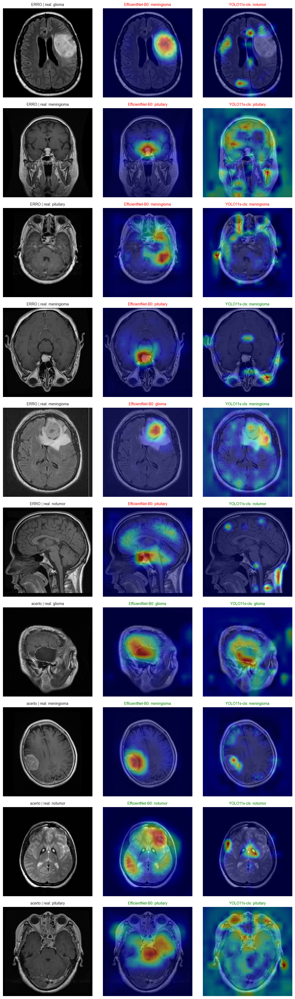

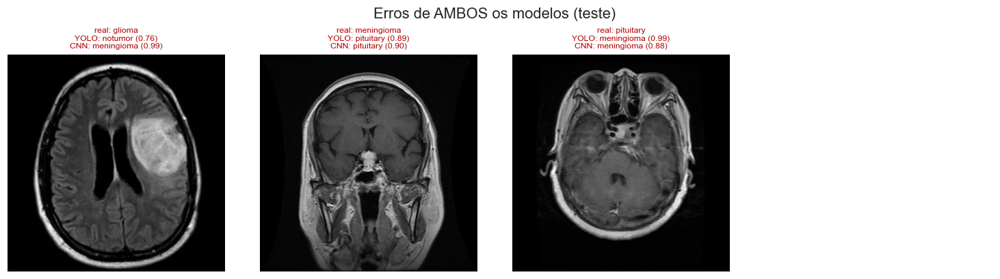

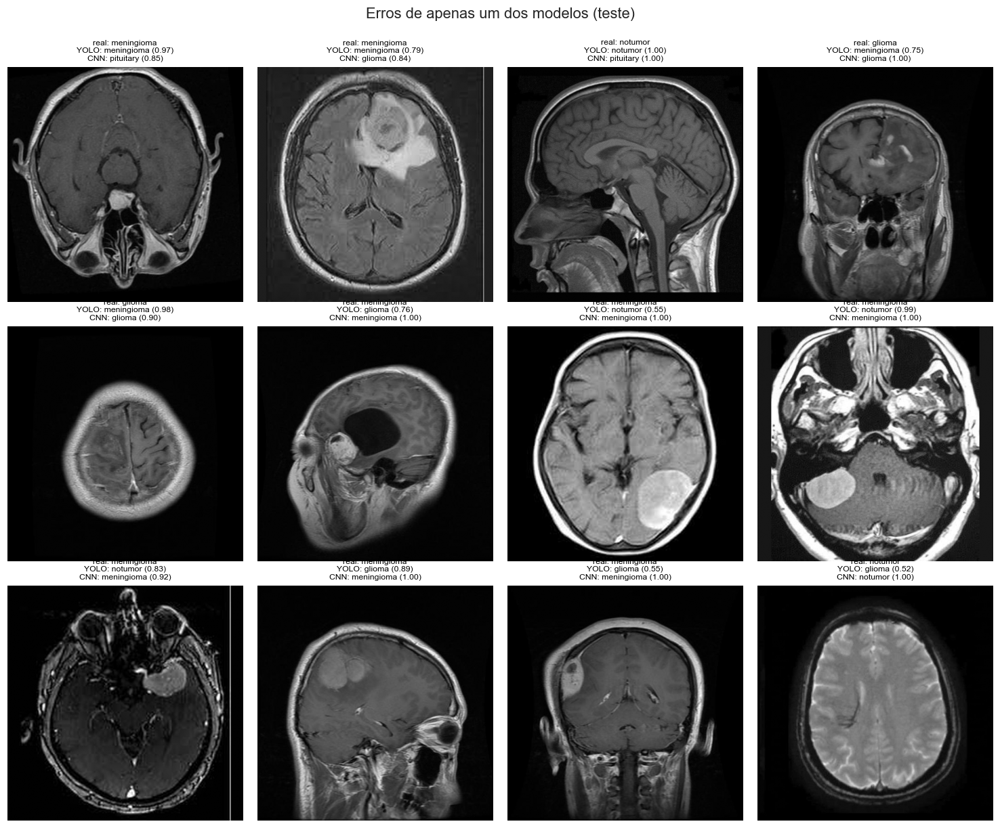

In [43]:
ER = []
for i, p in enumerate(CAM["test"]):
    e_y, e_c = PRED[NOME_Y]["test"][i] != Y["test"][i], PRED[NOME_C]["test"][i] != Y["test"][i]
    if e_y or e_c:
        ER.append({"Arquivo": Path(p).name, "idx": i, "Real": CLASSES[Y["test"][i]], "YOLO previu": CLASSES[PRED[NOME_Y]["test"][i]], "Conf. YOLO": PROB[NOME_Y]["test"][i].max(),
                   "CNN previu": CLASSES[PRED[NOME_C]["test"][i]], "Conf. CNN": PROB[NOME_C]["test"][i].max(), "Quem errou": "ambos" if (e_y and e_c) else ("só YOLO" if e_y else "só CNN"),
                   "Quase-duplicata no treino?": bool(ND[("test", "train")][i])})
ER = pd.DataFrame(ER).sort_values(["Quem errou", "Real"]).reset_index(drop=True); salvar_tab(ER.drop(columns="idx"), "3_comp_12_erros_teste.csv", index=False)
print(ER["Quem errou"].value_counts().to_dict()); display(ER.drop(columns="idx").round(3))
try:
    sel_idx = list(ER["idx"].head(N_GRADCAM)); rng2 = np.random.default_rng(SEED)
    sel_idx += [int(rng2.choice(np.where((Y["test"] == c) & (PRED[NOME_C]["test"] == c) & (PRED[NOME_Y]["test"] == c))[0])) for c in range(NC)]
    fig, ax = plt.subplots(len(sel_idx), 3, figsize=(10.5, 3.4 * len(sel_idx)))
    for r_, i in enumerate(sel_idx):
        im = Image.open(CAM["test"][i]).convert("RGB"); real = CLASSES[Y["test"][i]]; ax[r_, 0].imshow(im.convert("L"), cmap="gray"); ax[r_, 0].set_title(f"{'ERRO' if i in list(ER['idx']) else 'acerto'} | real: {real}", fontsize=9)
        for col, m in enumerate((NOME_C, NOME_Y), start=1):
            net, camada, tf = GC[m]; mapa, c = gradcam(net, camada, tf(im)); ax[r_, col].imshow(im.convert("L"), cmap="gray"); ax[r_, col].imshow(mapa, cmap="jet", alpha=.45)
            ax[r_, col].set_title(f"{m}: {CLASSES[c]}", fontsize=9, color="green" if CLASSES[c] == real else "red")
        for a in ax[r_]: a.axis("off")
    plt.tight_layout(); salvar_fig("3_comp_12_gradcam.png")
except Exception as e: print("Grad-CAM não pôde ser gerado:", type(e).__name__, str(e)[:300])
def galeria(df, titulo, arq, mx=12):
    df = df.head(mx)
    if df.empty: print(f"{titulo}: nenhuma imagem."); return
    cols = 4; rows = int(np.ceil(len(df) / cols)); fig, ax = plt.subplots(rows, cols, figsize=(3.4 * cols, 3.7 * rows)); ax = np.atleast_1d(ax).ravel()
    for a in ax: a.axis("off")
    for a, (_, r) in zip(ax, df.iterrows()):
        a.imshow(Image.open(CAM["test"][r["idx"]]).convert("L"), cmap="gray"); a.set_title(f"real: {r['Real']}\nYOLO: {r['YOLO previu']} ({r['Conf. YOLO']:.2f})\nCNN: {r['CNN previu']} ({r['Conf. CNN']:.2f})", fontsize=8, color="#b30000" if r["Quem errou"] == "ambos" else "black")
    fig.suptitle(titulo, y=1.0); plt.tight_layout(); salvar_fig(arq)
galeria(ER[ER["Quem errou"] == "ambos"], "Erros de AMBOS os modelos (teste)", "3_comp_12_erros_ambos.png"); galeria(ER[ER["Quem errou"] != "ambos"], "Erros de apenas um dos modelos (teste)", "3_comp_12_erros_um_modelo.png")

### 3.13 Eficiência comparada

,YOLO11s-cls,EfficientNet-B0,Razão CNN/YOLO
Parâmetros (M),5.448,4.013,0.737
GFLOPs/imagem,7.715,4.013,0.520
Peso em disco (MB),11.036,16.354,1.482
Latência mediana (ms),74.991,144.155,1.922
Latência p95 (ms),81.029,162.324,2.003


Determinismo (dif. máx.): {'YOLO11s-cls': 0.0, 'EfficientNet-B0': 0.0}


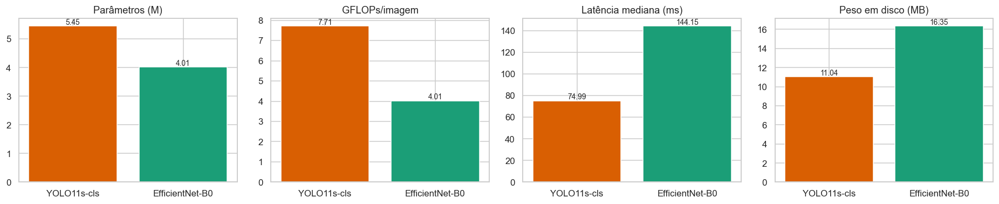

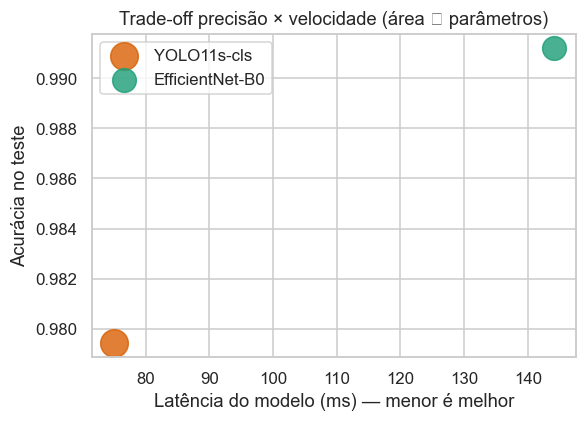

In [44]:
EFI = pd.DataFrame(R["efi"]); EFI["Razão CNN/YOLO"] = EFI[NOME_C] / EFI[NOME_Y]; display(EFI.round(3)); salvar_tab(EFI, "3_comp_13_eficiencia.csv"); print("Determinismo (dif. máx.):", R["det"])
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for a, met in zip(ax, ("Parâmetros (M)", "GFLOPs/imagem", "Latência mediana (ms)", "Peso em disco (MB)")):
    v = [EFI.loc[met, NOME_Y], EFI.loc[met, NOME_C]]; a.bar(MODELOS, v, color=[COR[m] for m in MODELOS]); a.set_title(met)
    for i, x_ in enumerate(v): a.text(i, x_, f"{x_:.2f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); salvar_fig("3_comp_13_eficiencia.png")
plt.figure(figsize=(5.5, 4))
for m in MODELOS: plt.scatter(EFI.loc["Latência mediana (ms)", m], accuracy_score(Y["test"], PRED[m]["test"]), s=EFI.loc["Parâmetros (M)", m] * 60, color=COR[m], alpha=.8, label=m)
plt.xlabel("Latência do modelo (ms) — menor é melhor"); plt.ylabel("Acurácia no teste"); plt.title("Trade-off precisão × velocidade (área ∝ parâmetros)"); plt.legend(); plt.tight_layout(); salvar_fig("3_comp_13_tradeoff.png")

### 3.14 Checklist de aprovação e placar final

In [45]:
CK = pd.concat([R["ck"][m].assign(Modelo=m) for m in MODELOS]); view = CK.pivot(index="Critério", columns="Modelo", values=["Valor", "Status"]).loc[list(R["ck"][NOME_Y]["Critério"])]
display(view.round(4)); salvar_tab(CK.drop(columns="ok"), "3_comp_14_checklist.csv", index=False)
resumo = CK.groupby("Modelo")["ok"].agg(lambda s: f"{int(sum(x is True for x in s))}/{int(sum(x is not None for x in s))} critérios atendidos"); print(resumo.to_dict())
T, V = "test", "val"; acc = lambda m, s: accuracy_score(Y[s], PRED[m][s]); sens = lambda m: R["clin"][m][R["clin"][m]["Conjunto"] == "teste"]["Sensibilidade"].iloc[0]
linhas = [("Acurácia — teste", acc(NOME_Y, T), acc(NOME_C, T), "max"), ("Acurácia — teste limpo", R["acc_limpo"][NOME_Y], R["acc_limpo"][NOME_C], "max"), ("Acurácia — valid", acc(NOME_Y, V), acc(NOME_C, V), "max"),
          ("F1 macro — teste", f1_score(Y[T], PRED[NOME_Y][T], average="macro"), f1_score(Y[T], PRED[NOME_C][T], average="macro"), "max"),
          ("MCC — teste", matthews_corrcoef(Y[T], PRED[NOME_Y][T]), matthews_corrcoef(Y[T], PRED[NOME_C][T]), "max"), ("AUC macro — teste", MET_AUC(NOME_Y), MET_AUC(NOME_C), "max"),
          ("Log-loss — teste", log_loss(Y[T], PROB[NOME_Y][T]), log_loss(Y[T], PROB[NOME_C][T]), "min"), ("ECE — teste", R["cal"][NOME_Y]["ECE"], R["cal"][NOME_C]["ECE"], "min"),
          ("Sensibilidade p/ tumor — teste", sens(NOME_Y), sens(NOME_C), "max"), ("Gap treino−valid (p.p.)", 100 * R["gap"][NOME_Y]["treino−valid"], 100 * R["gap"][NOME_C]["treino−valid"], "min"),
          ("Queda média sob perturbação (p.p.)", 100 * R["queda"][NOME_Y], 100 * R["queda"][NOME_C], "min"), ("Parâmetros (M)", EFI.loc["Parâmetros (M)", NOME_Y], EFI.loc["Parâmetros (M)", NOME_C], "min"),
          ("GFLOPs / imagem", EFI.loc["GFLOPs/imagem", NOME_Y], EFI.loc["GFLOPs/imagem", NOME_C], "min"), ("Latência do modelo (ms)", EFI.loc["Latência mediana (ms)", NOME_Y], EFI.loc["Latência mediana (ms)", NOME_C], "min"),
          ("Tempo de treino (min)", R["treino"][NOME_Y]["Tempo total (min)"], R["treino"][NOME_C]["Tempo total (min)"], "min")]
placar = pd.DataFrame(linhas, columns=["Critério", NOME_Y, NOME_C, "melhor_eh"])
def vence(r):
    if np.isnan(r[NOME_Y]) or np.isnan(r[NOME_C]) or np.isclose(r[NOME_Y], r[NOME_C], rtol=1e-4): return "empate"
    return (NOME_Y if r[NOME_Y] > r[NOME_C] else NOME_C) if r["melhor_eh"] == "max" else (NOME_Y if r[NOME_Y] < r[NOME_C] else NOME_C)
placar["Vencedor"] = placar.apply(vence, axis=1); placar = placar.drop(columns="melhor_eh"); display(placar.style.hide(axis="index").format({NOME_Y: "{:.4f}", NOME_C: "{:.4f}"})); salvar_tab(placar, "3_comp_14_placar.csv", index=False)
cont_v = placar["Vencedor"].value_counts(); print("Critérios vencidos:", cont_v.to_dict())

Valor              \
Modelo                                         EfficientNet-B0 YOLO11s-cls   
Critério                                                                     
Acurácia no teste                                     0.991189    0.979442   
Acurácia no teste LIMPO (sem quase-duplicatas)        0.989474    0.977193   
Menor recall entre as classes (teste)                 0.982955    0.960227   
Sensibilidade p/ tumor (teste)                             1.0    0.992381   
AUC macro (teste)                                      0.99988    0.998371   
Log-loss (teste)                                      0.033882    0.078005   
ECE — calibração (teste)                              0.008708    0.004991   
Gap treino − valid (variância)                        0.011188    0.028384   
|Gap valid − teste|                                   0.002792    0.008449   
Queda média de acurácia sob perturbação               0.223485    0.204545   
Determinismo (dif. máx. de probabilidade)                  0.0         0.0   

                                                        Status              
Modelo                                         EfficientNet-B0 YOLO11s-cls  
Critério                                                                    
Acurácia no teste                                            ✅           ✅  
Acurácia no teste LIMPO (sem quase-duplicatas)               ✅           ✅  
Menor recall entre as classes (teste)                        ✅           ✅  
Sensibilidade p/ tumor (teste)                               ✅           ✅  
AUC macro (teste)                                            ✅           ✅  
Log-loss (teste)                                             ✅           ✅  
ECE — calibração (teste)                                     ✅           ✅  
Gap treino − valid (variância)                               ✅           ✅  
|Gap valid − teste|                                          ✅           ✅  
Queda média de acurácia sob perturbação                      ❌           ❌  
Determinismo (dif. máx. de probabilidade)                    ✅           ✅

{'EfficientNet-B0': '10/11 critérios atendidos', 'YOLO11s-cls': '10/11 critérios atendidos'}


Critério,YOLO11s-cls,EfficientNet-B0,Vencedor
Acurácia — teste,0.9794,0.9912,EfficientNet-B0
Acurácia — teste limpo,0.9772,0.9895,EfficientNet-B0
Acurácia — valid,0.9710,0.9884,EfficientNet-B0
F1 macro — teste,0.9794,0.9914,EfficientNet-B0
MCC — teste,0.9726,0.9882,EfficientNet-B0
AUC macro — teste,0.9984,0.9999,EfficientNet-B0
Log-loss — teste,0.0780,0.0339,EfficientNet-B0
ECE — teste,0.0050,0.0087,YOLO11s-cls
Sensibilidade p/ tumor — teste,0.9924,1.0000,EfficientNet-B0
Gap treino−valid (p.p.),2.8384,1.1188,EfficientNet-B0


Critérios vencidos: {'EfficientNet-B0': 12, 'YOLO11s-cls': 3}


In [46]:
mc_t, mc_v = MC[MC["Conjunto"] == "teste"].iloc[0], MC[MC["Conjunto"] == "validação"].iloc[0]; acc_ = {m: acc(m, "test") for m in MODELOS}; melhor = max(acc_, key=acc_.get); outro = [m for m in MODELOS if m != melhor][0]
d_t = R["boot"][NOME_C]["test"]["acc"] - R["boot"][NOME_Y]["test"]["acc"]; icd = ic(d_t); fmt = lambda x: f"{x:.2%}"
if mc_t["p McNemar (exato)"] < .05: veredito = "diferença estatisticamente significativa a 5%"
elif icd[0] > 0 or icd[1] < 0: veredito = "evidência LIMÍTROFE: o IC do bootstrap exclui 0 por pouco, mas o McNemar não é significativo a 5%"
else: veredito = "diferença NÃO significativa a 5%"
txt = f"""
### Conclusão da comparação (gerada automaticamente a partir desta execução)

**Desempenho.** No teste ({len(Y['test'])} imagens): **{melhor}** = {fmt(acc_[melhor])} ({int((PRED[melhor]['test']!=Y['test']).sum())} erros) × **{outro}** = {fmt(acc_[outro])} ({int((PRED[outro]['test']!=Y['test']).sum())} erros).
No teste **limpo** (sem quase-duplicatas do treino): YOLO {fmt(R['acc_limpo'][NOME_Y])} | CNN {fmt(R['acc_limpo'][NOME_C])}. AUC macro: YOLO {MET_AUC(NOME_Y):.4f} | CNN {MET_AUC(NOME_C):.4f}. Log-loss: YOLO {log_loss(Y['test'], PROB[NOME_Y]['test']):.4f} | CNN {log_loss(Y['test'], PROB[NOME_C]['test']):.4f}.

**A diferença é real?** Teste: McNemar p = {mc_t['p McNemar (exato)']:.4f} e IC95% da diferença de acurácia (CNN − YOLO) [{icd[0]:+.2%}; {icd[1]:+.2%}] → {veredito}. Validação (1 379 imagens): p = {mc_v['p McNemar (exato)']:.4g} ({mc_v['Significativo (p<0,05)']}); o valid também guiou a escolha do melhor epoch.
O ensemble (média das probabilidades) chegou a {fmt(mc_t['Acc ensemble'])} no teste.

**Variância.** gap treino−valid: YOLO {100*R['gap'][NOME_Y]['treino−valid']:.2f} p.p. | CNN {100*R['gap'][NOME_C]['treino−valid']:.2f} p.p.; valid−teste: YOLO {100*R['gap'][NOME_Y]['valid−teste']:+.2f} | CNN {100*R['gap'][NOME_C]['valid−teste']:+.2f} p.p.

**Clínico.** Sensibilidade p/ tumor no teste: YOLO {sens(NOME_Y):.2%} | CNN {sens(NOME_C):.2%}.

**Robustez.** Queda média de acurácia sob perturbações: YOLO {100*R['queda'][NOME_Y]:.1f} p.p. | CNN {100*R['queda'][NOME_C]:.1f} p.p.

**Eficiência.** Parâmetros: YOLO {EFI.loc['Parâmetros (M)', NOME_Y]:.2f} M | CNN {EFI.loc['Parâmetros (M)', NOME_C]:.2f} M. GFLOPs: {EFI.loc['GFLOPs/imagem', NOME_Y]:.1f} | {EFI.loc['GFLOPs/imagem', NOME_C]:.1f}. Latência do modelo ({device.type}): {EFI.loc['Latência mediana (ms)', NOME_Y]:.0f} ms | {EFI.loc['Latência mediana (ms)', NOME_C]:.0f} ms.

**Checklist:** {', '.join(f'{m}: {v}' for m, v in resumo.items())}. **Placar:** {', '.join(f'{k}: {v}' for k, v in cont_v.items())}.
**Vazamento:** {dup_teste_treino} imagens de teste ({100*dup_teste_treino/len(Y['test']):.1f}%) têm quase-duplicata no treino.
"""
display(Markdown(txt)); (PASTA_SAIDA / "3_comp_conclusao.md").write_text(txt, encoding="utf-8")


### Conclusão da comparação (gerada automaticamente a partir desta execução)

**Desempenho.** No teste (681 imagens): **EfficientNet-B0** = 99.12% (6 erros) × **YOLO11s-cls** = 97.94% (14 erros).
No teste **limpo** (sem quase-duplicatas do treino): YOLO 97.72% | CNN 98.95%. AUC macro: YOLO 0.9984 | CNN 0.9999. Log-loss: YOLO 0.0780 | CNN 0.0339.

**A diferença é real?** Teste: McNemar p = 0.0574 e IC95% da diferença de acurácia (CNN − YOLO) [+0.15%; +2.20%] → evidência LIMÍTROFE: o IC do bootstrap exclui 0 por pouco, mas o McNemar não é significativo a 5%. Validação (1 379 imagens): p = 3.032e-06 (SIM); o valid também guiou a escolha do melhor epoch.
O ensemble (média das probabilidades) chegou a 99.27% no teste.

**Variância.** gap treino−valid: YOLO 2.84 p.p. | CNN 1.12 p.p.; valid−teste: YOLO -0.84 | CNN -0.28 p.p.

**Clínico.** Sensibilidade p/ tumor no teste: YOLO 99.24% | CNN 100.00%.

**Robustez.** Queda média de acurácia sob perturbações: YOLO 20.5 p.p. | CNN 22.3 p.p.

**Eficiência.** Parâmetros: YOLO 5.45 M | CNN 4.01 M. GFLOPs: 7.7 | 4.0. Latência do modelo (cpu): 75 ms | 144 ms.

**Checklist:** EfficientNet-B0: 10/11 critérios atendidos, YOLO11s-cls: 10/11 critérios atendidos. **Placar:** EfficientNet-B0: 12, YOLO11s-cls: 3.
**Vazamento:** 101 imagens de teste (14.8%) têm quase-duplicata no treino.


1333

### Limitações e cuidados
- **Uma execução de treino por modelo (seed 42).** Não medimos variância *entre treinos*; os ICs capturam só a variância da amostra de teste. Para isso, repita com outras seeds ou use validação cruzada.
- **Mesmo dataset (Roboflow, CC BY 4.0) em treino, valid e teste:** a validação é *interna*; não há garantia em outro hospital, scanner ou protocolo (validação externa).
- **Vazamento treino→teste/valid:** medido pela diferença de pixel em miniaturas 32×32 (limiar `DUP_LIM`); o teste limpo mostra o efeito. O `valid` também é afetado, e ele escolheu o melhor epoch de cada modelo.
- **Receitas de treino diferentes** (épocas, congelamento, dropout, augmentations): parte da diferença entre modelos pode vir da receita, não da arquitetura.
- **LR e `T_max` da CNN:** o LR é reconstruído por fórmula; o `Treinamento_CNN.ipynb` salvo em disco mostra `EPOCAS = 40`, mas o histórico atual tem 100 épocas (retreino) — o notebook assume `T_max` = nº de épocas treinadas.
- **Metas do checklist** são escolhas do grupo (dicionário `CRIT`), não padrões clínicos.
- Trabalho acadêmico: **não é um dispositivo médico** e não deve apoiar diagnóstico real.